# RoadLogic, journal version: what changed

Branch `feature/keep`. Everything in this notebook is produced by running the pipeline here: the
specifications are planned by clingo, executed by Frenetix and checked by the monitor. A full run
takes about 15 minutes. Finished experiments are cached in `demo_output/`, so a second run is quick.

**Status in one paragraph.** The `keep` constraint works end to end: it is parsed, encoded in the
ASP planning problem, and checked on the simulated trace. Speed is a new modifier, durations are
honoured, and contradicting specifications are reported as having no plan. The monitor now checks
keeps and the scenario duration. The Frenetix speed patch helped a single car hold a speed but caused a
collision with two cars. Section 8 has the cause, and a fix that handles both, not yet the default. The monitor now has
clocks, so a duration on any segment is checked (section 11).

| where | what |
|---|---|
| this notebook | the experiments, with specs, commands, new code and outputs |
| `demo_output/<experiment>/` | every intermediate file of each run: ASP program, plan, scenario, trace, animations, verdict |
| `docs/new_features.md` | the plain list of new features, for the email |
| `docs/review-queue.md`, section 0 | the code worth reviewing, in order |
| `.claude/PLAN.md`, end | decisions and where to continue |

Sections 1 to 6 are the features, 7 to 11 are experiments about simulation.

In [1]:
import os, sys, warnings
from collections import defaultdict
while not os.path.exists("planning") and os.getcwd() != "/":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("tests"))
warnings.simplefilter("ignore")

import pandas as pd
import matplotlib.pyplot as plt
from demo_pipeline import (OUT, PAPER, RECOMMENDED, PATCHED, draw_automaton, monitor_verdict,
                           run_experiment, show_code, show_images, show_lines,
                           simulation_folder, simulation_length)
from plan_checks import CONTROLLER_LP, HERE, Planner, goal_witnesses, lanes_of, speeds_of
from planning.asp.generate_plans import NoModelException

def spec(name):
    return os.path.join(HERE, name)

def plan_for(name, n=1, imax=12):
    import tempfile
    out = tempfile.mkdtemp(prefix="nb_plan_")
    planner = Planner(spec(name), out_path=out)
    return planner.plans(n=n, external_rules=[CONTROLLER_LP], visualize=False, imax=imax), out, planner

print("outputs go to", OUT)

outputs go to /home/figlerg/dev/artifact_iccps26/roadlogic/demo_output


## 1. Keep a lane for the whole scenario

**What is new.** `keep(<expression>)` from the standard. Written as a scenario member it must hold
at every step of the scenario. The planner encodes it as an integrity constraint, so a plan that
breaks it is never produced. The monitor checks the same thing on the simulated trace.

**Spec.** `tests/keep_scenario_scope.osc`, the usual overtake, but car1 must stay in lane 2 throughout.

**Command.** Planning only: `python tests/run_keep_tests.py keep_scenario_scope.osc -v`.
The full pipeline is in `demo_output/e1_keep_one_lane/commands.sh`.

In [2]:
print(open(spec("keep_scenario_scope.osc")).read())

# Scenario-scoped keep: the invariant is declared as a scenario member, so per 7.3.11.2 it
# holds for the whole lifetime of the scenario, across every phase of every actor.
# Contrast with keep.osc, where the same constraint sits inside a single behavior invocation.
# car1 is pinned to lane 2 because lanes are 1..3 and ego needs a lane strictly left of car1.
#
# The final gap is 13m..25m rather than the 5m..10m used in exp_002_b, and that difference is
# forced by the model rather than by taste. Merging back into car1's lane triggers the "right
# change version" rule in dynamics.lp, which forbids the move unless car1 is more than
# safety_distance_back = 7 behind ego's previous segment. A lane change also needs
# Vel_lon >= min_change_speed = 6 per controller.lp. Together the gap right after merging is at
# least 6 + 7 = 13, so a 5m..10m goal is unsatisfiable.
#
# exp_002_b gets away with 5m..10m only because car1 is free to change lane there and does:
# its baseline trace is [2,2,2,2

In [3]:
# the new code: a keep is written as its own negation, and that becomes an integrity constraint
from planning.intermediate_structure.Constraint import Invariant
show_code(Invariant.asp_violation_bodies, 22)

planning/intermediate_structure/Constraint.py:889

  889      def asp_violation_bodies(self):
  890          """Rule bodies for `#program check(t)` that hold exactly when the invariant is broken at t.
  891  
  892          A keep for the whole scenario turns each into an integrity constraint. A keep inside a
  893          behavior invocation turns each into keep_broken(i,t), see Planner._invocation_keep_rules.
  894          """
  895          c = self.constraint
  896  
  897          if isinstance(c, AbsoluteConstraint):
  898              value = c.value
  899              if isinstance(value, float) and value.is_integer():
  900                  value = int(value)
  901  
  902              op = self.FORBIDDEN.get(c.relation)
  903              if op is None:
  904                  raise NotImplementedError(f"Cannot negate relation {c.relation} for an invariant.")
  905  
  906              var = 'X'
  907              return [f"{self._holds(c.actor, c.modifier, var)}, {var} {op}

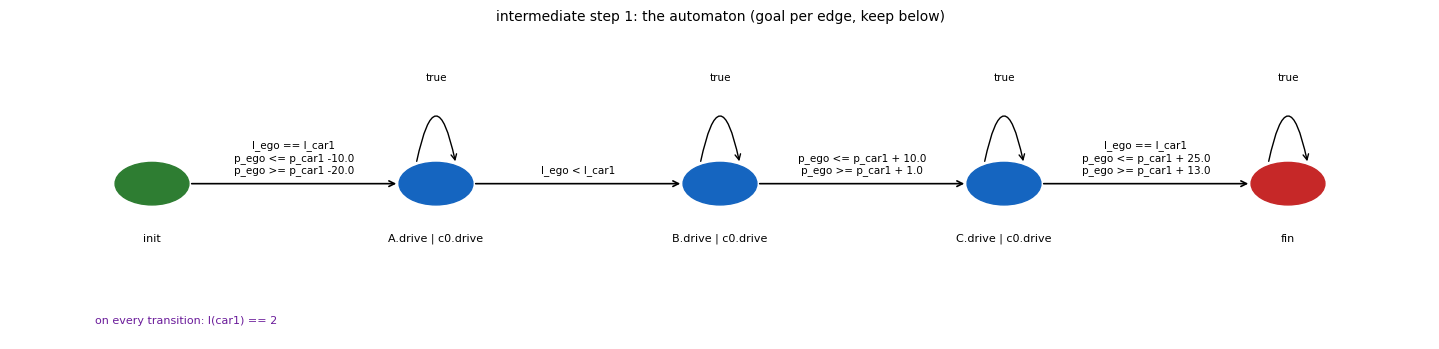

intermediate step 2: what the keep becomes in the ASP program (instance.lp)

goal(T1,T2,T3,t) :-  goal1(T1),goal2(T2),goal3(T3), 0 <= T1<=T2<=T3 <= t, 3 <= T3 <= 20.
:- query(t), not goal(_,_,_,t).
:- query(t), goal(_,_,_,t-1).
:- holds(state(car1, loc(_,X), dyn(_,_)), t), X != 2.

intermediate step 3: the plan (plan.txt)

last step: 9
goal times, one tuple per valid split: [(3, 4, 9), (3, 5, 9), (4, 4, 9), (4, 5, 9), (5, 5, 9)]

car1
  t [s]          0    1    2    3    4    5    6    7    8    9
  position      10   11   14   17   25   26   27   34   36   37
  lane           2    2    2    2    2    2    2    2    2    2
  speed [mps]    1    3    3    8    1    1    7    2    1    3

ego
  t [s]          0    1    2    3    4    5    6    7    8    9
  position       0    1    8   14   26   36   44   45   54   61
  lane           2    2    2    1    1    1    1    1    1    2
  speed [mps]    1    7    6   12   10    8    1    9    7    1



In [4]:
e1 = run_experiment("e1_keep_one_lane", spec("keep_scenario_scope.osc"), RECOMMENDED)
fig = draw_automaton(spec("keep_scenario_scope.osc"), "intermediate step 1: the automaton (goal per edge, keep below)")
plt.show()
print("intermediate step 2: what the keep becomes in the ASP program (instance.lp)\n")
show_lines(f"{e1}/instance.lp", [":- holds", "goal("])
print("\nintermediate step 3: the plan (plan.txt)\n")
print(open(f"{e1}/plan.txt").read())

"intermediate step 4: the plan, as the solver sees it",output: the simulation

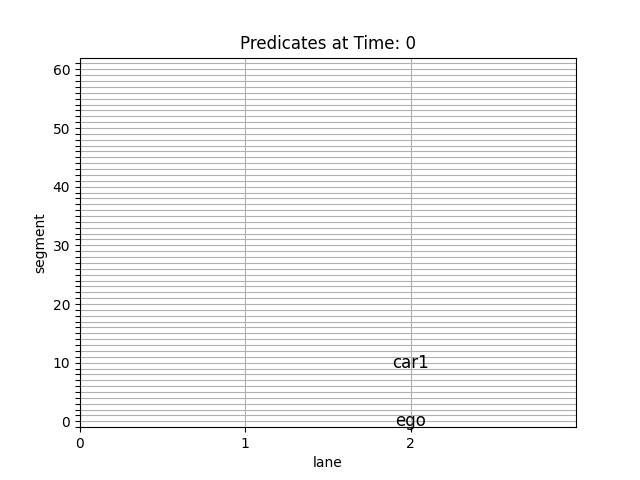
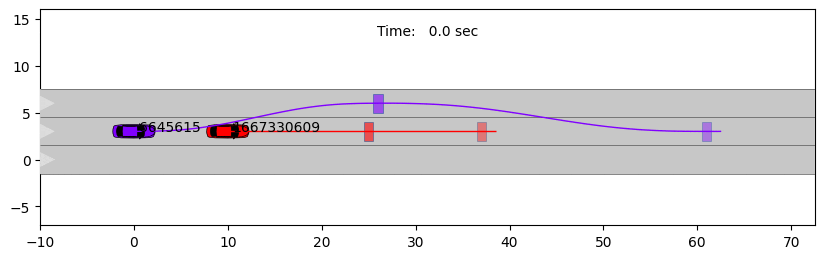

monitor verdict on the simulated trace: POSITIVE
Watch car1: it never leaves its lane while the other car overtakes it.


In [5]:
show_images([("intermediate step 4: the plan, as the solver sees it", f"{e1}/plan.gif"),
             ("output: the simulation", f"{e1}/simulation.gif")])
print("monitor verdict on the simulated trace:", open(f"{e1}/monitor.txt").readline().strip())
print("Watch car1: it never leaves its lane while the other car overtakes it.")

## 2. Keeps on consecutive segments

**What is new.** A keep inside one behavior holds only while that behavior runs. Two neighbouring
segments get windows that tile the plan, `[T0, T1)` and `[T1, T2]`, so `lane == 1` followed by
`lane == 2` is satisfiable. It was not, before the windows stopped sharing their boundary step.

**Spec.** `tests/keep_lane_change_from_rest.osc`. The car starts from rest, as every simulated car
does, so it accelerates before it changes lane.

**Command.** `python tests/run_keep_tests.py keep_adjacent_phases.osc -v` for the planning side.

In [6]:
print(open(spec("keep_lane_change_from_rest.osc")).read())
from planning.Planner import Planner as _P
show_code(_P._invocation_keep_rules, 40)

# The same two keeps as keep_adjacent_phases.osc, lane 1 and then lane 2, but without fixing the
# speed at the start. Every simulated car starts from a standstill, so a start speed can never
# hold in simulation and the monitor rejects the trace on its first sample. Here the planner has
# to accelerate on its own before the lane change (controller.lp asks for at least 6mps for one),
# which a simulation can follow.

scenario lane_change:
    car1: car

    do serial:
        A0: car1.drive() with:
            lane(1, at: start)
            position(0m, at: start)
            keep(car1.lane == 1)

        A1: car1.drive() with:
            lane(2, at: end)
            keep(car1.lane == 2)

planning/Planner.py:235

  235      def _invocation_keep_rules(self, G, aut_path):
  236          """ASP rules and goal-rule literals for keeps declared inside a behavior invocation.
  237  
  238          Phase k is the k-th node of the chosen path and runs from goal time T(k-1) to Tk, with
  239   

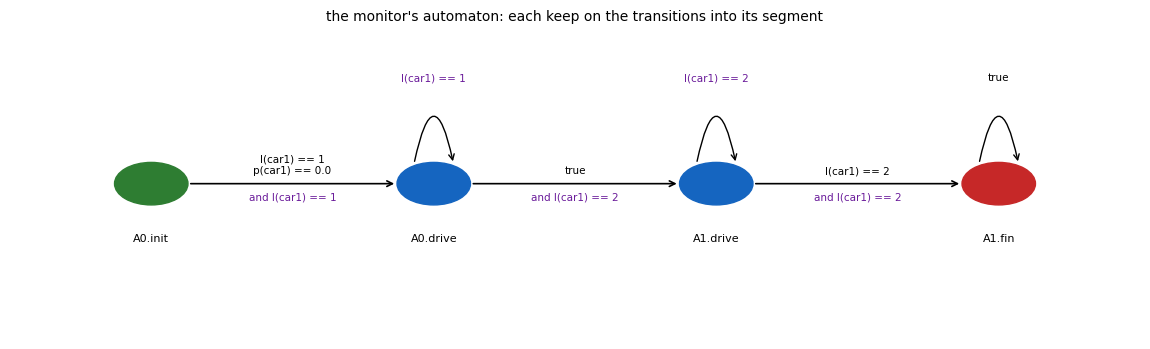

every rule the planner generates for the two keeps (instance.lp), explained below

goal(T1,T2,t) :-  goal1(T1),goal2(T2), 0 <= T1<=T2 <= t, keep_held(1,0,T1 - 1), keep_held(2,T1,T2).
:- query(t), not goal(_,_,t).
:- query(t), goal(_,_,t-1).
% keep 1: keep[A0.drive](l(car1) == 1), held from 0 to T1 - 1
keep_broken(1,t) :- holds(state(car1, loc(_,X), dyn(_,_)), t), X != 1.
keep_held(1,t,t) :- time(t), not keep_broken(1,t).
keep_held(1,t,t-1) :- time(t).
keep_window(1,0,T1 - 1,t) :- goal(T1,_,t).
% keep 2: keep[A1.drive](l(car1) == 2), held from T1 to T2
keep_broken(2,t) :- holds(state(car1, loc(_,X), dyn(_,_)), t), X != 2.
keep_held(2,t,t) :- time(t), not keep_broken(2,t).
keep_held(2,t,t-1) :- time(t).
keep_window(2,T1,T2,t) :- goal(T1,T2,t).
keep_held(I,Ta,t) :- keep_held(I,Ta,t-1), not keep_broken(I,t).

last step: 3
goal times, one tuple per valid split: [(3, 3)]
keep windows (keep, from, to): [(1, 0, 2), (2, 3, 3)]

car1
  t [s]          0    1    2    3
  position       0    1    9

In [7]:
e2 = run_experiment("e2_keep_two_lanes", spec("keep_lane_change_from_rest.osc"), RECOMMENDED)
fig = draw_automaton(spec("keep_lane_change_from_rest.osc"), "the monitor's automaton: each keep on the transitions into its segment")
plt.show()
print("every rule the planner generates for the two keeps (instance.lp), explained below\n")
show_lines(f"{e2}/instance.lp", ["% keep", "keep_broken", "keep_held", "keep_window", "goal("])
print("\n" + open(f"{e2}/plan.txt").read())

### How the keep atoms work

Each keep gets a number, here 1 for `lane == 1` on segment A0 and 2 for `lane == 2` on segment A1,
and three kinds of atoms:

- **`keep_broken(i, t)`**: keep i is violated at step t. This is the keep written as its own negation:
  for `keep(car1.lane == 1)` it holds when car1's lane at step t is anything but 1.
- **`keep_held(i, From, To)`**: keep i holds at every step from From to To. It is built up one step at
  a time. A single step holds when it is not broken, `keep_held(1,t,t) :- time(t), not keep_broken(1,t)`.
  A stretch that holds up to t-1 grows by one step when step t is not broken either,
  `keep_held(I,Ta,t) :- keep_held(I,Ta,t-1), not keep_broken(I,t)`. So the solver ends up with one
  atom for every stretch of consecutive unbroken steps. One extra base case,
  `keep_held(i,t,t-1) :- time(t)`, is the empty stretch, for a segment of length zero.
- **The goal rule** then asks each keep for the stretch its segment covers. A0 runs from step 0 up to
  but not including T1, so it needs `keep_held(1, 0, T1-1)`. A1 runs from T1 to T2, so it needs
  `keep_held(2, T1, T2)`. A split of the plan into segments, the choice of T1 and T2, only counts if
  both atoms exist.

**`keep_window(i, From, To, t)` does not constrain anything.** It records, for each split the goal rule
accepted, the stretch each keep had to cover. It exists so the tests and this notebook can check a keep
on exactly the steps it applied to. It carries the horizon t as a fourth argument because incremental
solving does not allow the same atom to be defined again at a later horizon.

The next cell takes these atoms straight from the solved plan.

In [8]:
import pickle

model = pickle.load(open(os.path.join(OUT, "_work", "e2_keep_two_lanes", "out", "serialized_models", "0001.pkl"), "rb"))
atoms = {str(a) for a in model}
lanes = lanes_of(model, "car1")
last = len(lanes) - 1

# 1. which steps break which keep
display(pd.DataFrame([{"step": t, "car1 lane": lane,
                       "keep 1 (lane == 1) broken": "yes" if f"keep_broken(1,{t})" in atoms else "",
                       "keep 2 (lane == 2) broken": "yes" if f"keep_broken(2,{t})" in atoms else ""}
                      for t, lane in enumerate(lanes)]).set_index("step"))

# 2. the stretches the solver derived, from the keep_held atoms
held = defaultdict(list)
for a in model:
    if a.name == "keep_held":
        i, start, end = a.arguments
        held[i].append((start, end))
for i in sorted(held):
    stretches = [f"{s}..{e}" for s, e in sorted(held[i]) if s <= e]
    print(f"keep_held({i}, From, To) for the stretches {', '.join(stretches)}, plus the empty ones")

# 3. every split of the plan into the two segments, and what the goal rule makes of it
print(f"\nthe goal rule, for every T1 with T2 = {last} (the last step, where goal2 holds):")
for t1 in range(last + 1):
    first, second = f"keep_held(1,0,{t1 - 1})", f"keep_held(2,{t1},{last})"
    verdict = "accepted" if first in atoms and second in atoms else "rejected"
    print(f"  T1 = {t1}: {first} {'derived' if first in atoms else 'missing'}, "
          f"{second} {'derived' if second in atoms else 'missing'}  ->  {verdict}")

windows = sorted(tuple(a.arguments[:3]) for a in model if a.name == "keep_window")
print(f"\nkeep_window records the accepted split: {windows}, as (keep, from, to)")
print("The keeps leave exactly one split: the segment boundary falls on the step of the lane change.")

,car1 lane,keep 1 (lane == 1) broken,keep 2 (lane == 2) broken
step,,,
0,1,,yes
1,1,,yes
2,1,,yes
3,2,yes,


keep_held(1, From, To) for the stretches 0..0, 0..1, 0..2, 1..1, 1..2, 2..2, plus the empty ones
keep_held(2, From, To) for the stretches 3..3, plus the empty ones

the goal rule, for every T1 with T2 = 3 (the last step, where goal2 holds):
  T1 = 0: keep_held(1,0,-1) derived, keep_held(2,0,3) missing  ->  rejected
  T1 = 1: keep_held(1,0,0) derived, keep_held(2,1,3) missing  ->  rejected
  T1 = 2: keep_held(1,0,1) derived, keep_held(2,2,3) missing  ->  rejected
  T1 = 3: keep_held(1,0,2) derived, keep_held(2,3,3) derived  ->  accepted

keep_window records the accepted split: [(1, 0, 2), (2, 3, 3)], as (keep, from, to)
The keeps leave exactly one split: the segment boundary falls on the step of the lane change.


the plan,the simulation

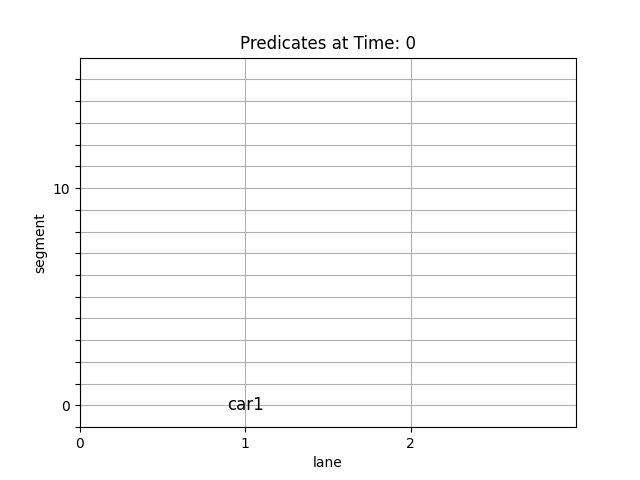
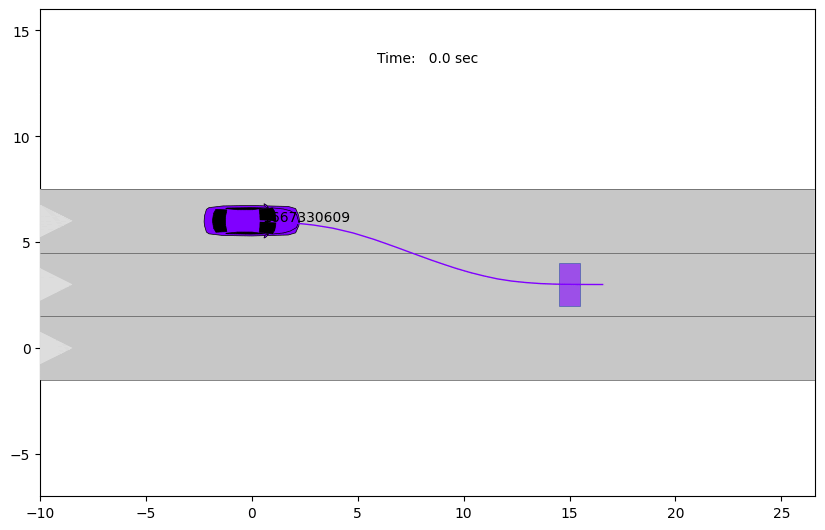

monitor verdict: POSITIVE
Watch the car: one lane change, after it has picked up speed, and no other.


In [9]:
show_images([("the plan", f"{e2}/plan.gif"), ("the simulation", f"{e2}/simulation.gif")])
print("monitor verdict:", open(f"{e2}/monitor.txt").readline().strip())
print("Watch the car: one lane change, after it has picked up speed, and no other.")

## 3. The standard's shorthands `keep_lane()` and `keep_speed()`

**What is new.** The domain model defines `keep_lane()` as `keep(actor.lane == lane)` against a
fresh parameter, which means "the lane never changes". Both forms now give the same invariant and
the same plans. No simulation needed, this is about the plans.

**Specs.** `tests/keep_lane_free.osc` (long form) and `tests/keep_lane_modifier.osc` (shorthand).

In [10]:
from planning.parse.TranslationGraphVisitor import TranslationGraphVisitor
show_code(TranslationGraphVisitor._build_stability_invariants)

rows, seen = [], {}
for name in ("keep_lane_free.osc", "keep_lane_modifier.osc"):
    plans, _, planner = plan_for(name, n=3)
    seen[name] = [(m.max_t, lanes_of(m, "car1"), lanes_of(m, "ego")) for m in plans]
    rows.append({"spec": name, "invariant": str(planner.translation_graph.invariants[0]),
                 "car1 lanes, first plan": seen[name][0][1]})
display(pd.DataFrame(rows).set_index("spec"))
print("identical first three plans:", seen["keep_lane_free.osc"] == seen["keep_lane_modifier.osc"])

planning/parse/TranslationGraphVisitor.py:568

  568      def _build_stability_invariants(self, modifier: str, arg_list: dict) -> set:
  569          if arg_list:
  570              raise ValueError(
  571                  f"{modifier}() takes no arguments, got {arg_list}. To fix a value, write for "
  572                  f"example lane(2) or keep(car1.lane == 2) instead."
  573              )
  574          # 'self' is replaced by the invoking actor in visitBehavior_invocation, which also sets
  575          # the scope to that invocation.
  576          return {StabilityInvariant("self", self.STABILITY_MODIFIERS[modifier])}


Initial setup saved to temporary file /tmp/nb_plan_cm_58q_i/instance.lp!
Solving... t = 0
Solving... t = 1


Solving... t = 2
Solving... t = 3


Initial setup saved to temporary file /tmp/nb_plan_qy5sa7du/instance.lp!
Solving... t = 0


Solving... t = 1
Solving... t = 2


Solving... t = 3


,invariant,"car1 lanes, first plan"
spec,,
keep_lane_free.osc,"keep[scenario](car1.l == car1_lane, constant)","[2, 2, 2, 2]"
keep_lane_modifier.osc,"keep[c0.drive](car1.l == <free>, constant)","[2, 2, 2, 2]"


identical first three plans: True


## 4. Contradicting specifications have no plan

**What is new.** The standard describes inconsistent specifications (7.6.2.3) and gives no way to
detect them. Here an inconsistent specification is exactly an unsatisfiable ASP program. The
nonlocal case is the interesting one: no single step is impossible, only their interplay over time.

**Command.** `python tests/run_keep_tests.py` runs all of these among the keep tests.

In [11]:
rows = []
for name, note in [("keep_inconsistent_direct.osc", "two lane keeps on one car"),
                   ("keep_inconsistent_parallel.osc", "conflict across parallel branches"),
                   ("keep_inconsistent_nonlocal.osc", "only the interplay over time is impossible"),
                   ("duration_conflict_unsat.osc", "two phases of 3s or more inside 5s")]:
    try:
        plans, _, _ = plan_for(name)
        result = f"plan found at step {plans[0].max_t}"
    except NoModelException:
        result = "no plan, correctly"
    rows.append({"spec": name, "contradiction": note, "result": result})
display(pd.DataFrame(rows).set_index("spec"))

Initial setup saved to temporary file /tmp/nb_plan_5tnow1w6/instance.lp!
Solving... t = 0
Solving... t = 1
Solving... t = 2
Solving... t = 3
Solving... t = 4
Solving... t = 5
Solving... t = 6
Solving... t = 7
Solving... t = 8
Solving... t = 9
Solving... t = 10
Solving... t = 11
Initial setup saved to temporary file /tmp/nb_plan_ng6f6a6w/instance.lp!
Solving... t = 0
Solving... t = 1
Solving... t = 2


Solving... t = 3


Solving... t = 4


Solving... t = 5


Solving... t = 6


...

Initial setup saved to temporary file /tmp/nb_plan_vc15iyq5/instance.lp!
Solving... t = 0
Solving... t = 1
Solving... t = 2
Solving... t = 3
Solving... t = 4
Solving... t = 5
Solving... t = 6
Solving... t = 7
Solving... t = 8
Solving... t = 9
Solving... t = 10
Solving... t = 11
Initial setup saved to temporary file /tmp/nb_plan_9ydidoq4/instance.lp!
Solving... t = 0
Solving... t = 1
Solving... t = 2


Solving... t = 3


Solving... t = 4


Solving... t = 5


,contradiction,result
spec,,
keep_inconsistent_direct.osc,two lane keeps on one car,"no plan, correctly"
keep_inconsistent_parallel.osc,conflict across parallel branches,"no plan, correctly"
keep_inconsistent_nonlocal.osc,only the interplay over time is impossible,"no plan, correctly"
duration_conflict_unsat.osc,two phases of 3s or more inside 5s,"no plan, correctly"


## 5. Durations

**What is new.** `duration: [3s..20s]` on a composition or a single behavior used to be ignored. A
duration covering phases k1 to k2 now becomes `low <= T(k2) - T(k1-1) <= high` in the goal rule.

**Spec.** `tests/duration_invocation.osc`. **Command.** `python tests/run_duration_tests.py`.

In [12]:
from planning.Planner import Planner as _P
show_code(_P._duration_literals, 22)
plans, out, _ = plan_for("duration_invocation.osc", n=3)
print()
show_lines(f"{out}/instance.lp", ["% duration", "goal("])
for m in plans:
    print("plan: goal times", goal_witnesses(m), " so (T1-T0, T2-T1) =", [(a, b - a) for a, b in goal_witnesses(m)])

planning/Planner.py:212

  212      def _duration_literals(self, G, aut_path):
  213          """Goal-rule literals for the duration bounds, plus the top-level maximum if there is one.
  214  
  215          A duration covering phases k1..k2 bounds T(k2) - T(k1-1). Returns the literals as one
  216          string to append to the goal rule, the maximum of a duration that covers the whole plan,
  217          and comment lines for the instance.
  218          """
  219          literals, comments, cap = [], [], None
  220          last = f"T{len(aut_path) - 2}"
  221          for duration in sorted(G.durations, key=str):
  222              if not self._on_path(duration.labels, aut_path):
  223                  continue  # inside an alternative this path does not take
  224              start, end = self._phase_window(duration.labels, aut_path, str(duration))
  225              span = end if start == "0" else f"{end} - {start}"
  226              if duration.low == duration.high:
  227 

Solving... t = 4


Solving... t = 5



% duration[parallel](3..20s): from 0 to T2
% duration[the invocation A.drive](3..4s): from 0 to T1
% duration[the invocation B.drive](2..5s): from T1 to T2
goal(T1,T2,t) :-  goal1(T1),goal2(T2), 0 <= T1<=T2 <= t, 3 <= T2 <= 20, 3 <= T1 <= 4, 2 <= T2 - T1 <= 5.
:- query(t), not goal(_,_,t).
:- query(t), goal(_,_,t-1).
plan: goal times [(3, 5)]  so (T1-T0, T2-T1) = [(3, 2)]
plan: goal times [(3, 5)]  so (T1-T0, T2-T1) = [(3, 2)]
plan: goal times [(3, 5)]  so (T1-T0, T2-T1) = [(3, 2)]


## 5b. Durations, nested

**What it shows.** A duration can sit on any composition or invocation, at any depth. Each one bounds the
time from the start of its first phase to the end of its last, so it becomes one inequality over the
goal times, and nested durations just add inequalities over overlapping stretches. The solver has to
satisfy all of them at once, which is where the levels start constraining each other.

**Spec.** `tests/duration_nested_deep.osc`: a duration on the whole scenario, on a `parallel` and a
`serial` inside it, and on single invocations inside those. The path has three phases, (a, b), then c,
then d, with goal times T1, T2, T3.

**Command.** `python tests/run_duration_tests.py duration_nested_deep.osc -v`.

In [13]:
print(open(spec("duration_nested_deep.osc")).read())
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):   # keep the solver's progress lines out of the way
    plans, out, planner = plan_for("duration_nested_deep.osc", n=3)
print("each duration and the stretch of goal times it bounds, then the goal rule that carries them all:\n")
show_lines(f"{out}/instance.lp", ["% duration", "goal("])

t1, t2, t3 = goal_witnesses(plans[0])[0]
rows = []
for line in open(f"{out}/instance.lp"):
    if line.startswith("% duration["):
        name = line[len("% duration["):line.index("]")]
        bound = line[line.index("](") + 2:line.index(")")]
        start, end = line.rstrip().rsplit(": from ", 1)[1].split(" to ")
        value = {"0": 0, "T1": t1, "T2": t2, "T3": t3}
        rows.append({"duration on": name, "bound": bound, "covers": f"{start} to {end}",
                     "in this plan": f"{value[end] - value[start]}s"})
print(f"\nthe plan's goal times: T1 = {t1}, T2 = {t2}, T3 = {t3}")
display(pd.DataFrame(rows).set_index("duration on"))

# Durations at every level of nesting: the scenario, a parallel and a serial inside it, and single
# invocations inside those. The path through the automaton has three phases: (a, b), then c, then d.
# Each duration bounds the time from the start of its first phase to the end of its last one, so
#   whole scenario   T3 - 0   in [5, 9]
#   first, and a     T1 - 0   in [2, 3]
#   second           T3 - T1  in [3, 6]
#   c                T2 - T1  in [1, 2]
#   d                T3 - T2  in [2, 4]
# The bounds have to agree with each other, for instance second can last at most 2 + 4 = 6 because
# c and d can, and the whole scenario at least 2 + 1 + 2 = 5.

scenario nested_durations:
    car1: car
    car2: car

    do serial(duration: [5s..9s]):
        first: parallel(duration: [2s..3s]):
            a: car1.drive(duration: [2s..3s]) with:
                lane(1, at: start)
                position(0m, at: start)
            b: car2.drive() with:
                lane(same_as: car1, at: star

each duration and the stretch of goal times it bounds, then the goal rule that carries them all:

% duration[first: parallel](2..3s): from 0 to T1
% duration[second: serial](3..6s): from T1 to T3
% duration[serial](5..9s): from 0 to T3
% duration[the invocation a.drive](2..3s): from 0 to T1
% duration[the invocation c.drive](1..2s): from T1 to T2
% duration[the invocation d.drive](2..4s): from T2 to T3
goal(T1,T2,T3,t) :-  goal1(T1),goal2(T2),goal3(T3), 0 <= T1<=T2<=T3 <= t, 2 <= T1 <= 3, 3 <= T3 - T1 <= 6, 5 <= T3 <= 9, 2 <= T1 <= 3, 1 <= T2 - T1 <= 2, 2 <= T3 - T2 <= 4.
:- query(t), not goal(_,_,_,t).
:- query(t), goal(_,_,_,t-1).

the plan's goal times: T1 = 2, T2 = 3, T3 = 5


,bound,covers,in this plan
duration on,,,
first: parallel,2..3s,0 to T1,2s
second: serial,3..6s,T1 to T3,3s
serial,5..9s,0 to T3,5s
the invocation a.drive,2..3s,0 to T1,2s
the invocation c.drive,1..2s,T1 to T2,1s
the invocation d.drive,2..4s,T2 to T3,2s


### How the levels constrain each other

The same spec with one or two bounds changed. An outer bound that is longer than its parts can stretch
them, one that is shorter than the parts need leaves no plan, and so does an inner bound that cannot fit
inside its parent. In the last three the planner proves there is no plan, which is the inconsistency
detection from section 4 applied to timing.

In [14]:
import time as _time
base = open(spec("duration_nested_deep.osc")).read()
variants = [
    ("as written", {}),
    ("whole scenario [8s..9s]: the parts have to stretch",
     {"do serial(duration: [5s..9s])": "do serial(duration: [8s..9s])"}),
    ("whole scenario [3s..4s]: the parts need at least 2 + 1 + 2 = 5s",
     {"do serial(duration: [5s..9s])": "do serial(duration: [3s..4s])"}),
    ("d exactly 4s, second at most 4s: no time left for c, which needs 1s",
     {"d: car1.drive(duration: [2s..4s])": "d: car1.drive(duration: [4s..4s])",
      "second: serial(duration: [3s..6s])": "second: serial(duration: [3s..4s])"}),
    ("a exactly 3s inside first, which allows exactly 2s",
     {"a: car1.drive(duration: [2s..3s])": "a: car1.drive(duration: [3s..3s])",
      "first: parallel(duration: [2s..3s])": "first: parallel(duration: [2s..2s])"}),
]
rows = []
for k, (label, changes) in enumerate(variants):
    text = base
    for old, new in changes.items():
        assert old in text, old
        text = text.replace(old, new)
    path = os.path.join(OUT, f"nested_variant_{k}.osc")
    open(path, "w").write(text)
    started = _time.time()
    variant_out = os.path.join(OUT, f"nested_variant_{k}")
    os.makedirs(variant_out, exist_ok=True)
    try:
        with contextlib.redirect_stdout(io.StringIO()):
            found = Planner(path, out_path=variant_out).plans(
                n=1, external_rules=[CONTROLLER_LP], visualize=False, imax=12)
        result = "T1, T2, T3 = " + ", ".join(map(str, goal_witnesses(found[0])[0]))
    except NoModelException:
        result = "no plan"
    rows.append({"variant": label, "result": result, "seconds": round(_time.time() - started, 1)})
display(pd.DataFrame(rows).set_index("variant"))

,result,seconds
variant,,
as written,"T1, T2, T3 = 2, 3, 5",1.3
whole scenario [8s..9s]: the parts have to stretch,"T1, T2, T3 = 2, 4, 8",8.8
whole scenario [3s..4s]: the parts need at least 2 + 1 + 2 = 5s,no plan,0.6
"d exactly 4s, second at most 4s: no time left for c, which needs 1s",no plan,15.4
"a exactly 3s inside first, which allows exactly 2s",no plan,13.9


### What the monitor makes of it

The monitor checks the same six durations on a trace. A duration whose stretch starts with the scenario
was entered at time 0, so it is a plain guard on the current time. One that starts later, at T1 or T2,
needs the time its stretch began, so it gets a clock per run, from section 11.

Nothing pins where `first` ends, since neither `a` nor `b` has a goal at its end. So a slowed-down
trace can still pass: the monitor looks for any way to split it into segments that fits every
bound. A duration's upper bound only bites when a goal forces its segment to run long.

guards on the current time: duration[first: parallel](2..3s), duration[serial](5..9s), duration[the invocation a.drive](2..3s)
clocks per run            : duration[second: serial](3..6s), duration[the invocation c.drive](1..2s), duration[the invocation d.drive](2..4s)


,verdict
trace,
"the plan's own trace, T = (2, 3, 5)",accepted
"twice as fast: the trace lasts under 3s, the scenario needs at least 5s",rejected
"1.7 times slower: still fits, the monitor splits the trace into segments differently",accepted
"2.5 times slower: car1 reaches lane 2 only at 10s, the scenario has to end by 9s",rejected


the plan,the simulation

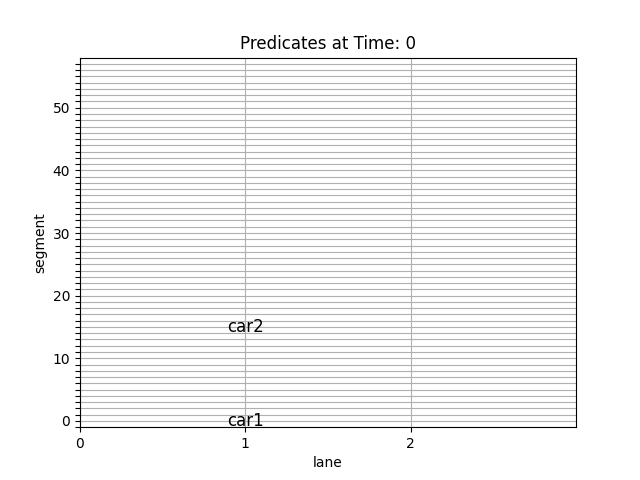
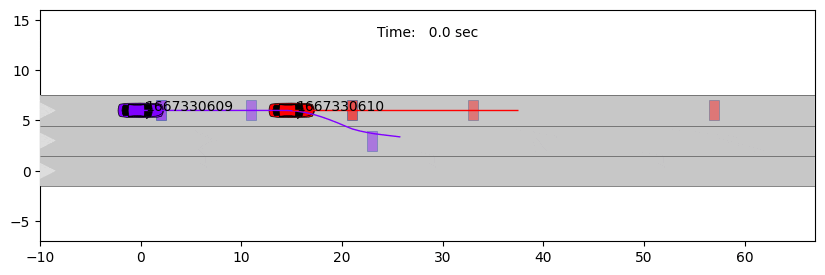

monitor verdict on the simulation: negative
car2 leaves the simulation at 4.2s, once it has passed its last waypoint, and the monitor
stops at the first sample where a car is missing. car1 changes lane only at 5.0s, which is the
end of d, so the checked trace stops before the scenario does. That is the open execution problem
from the benchmark, cars leaving the simulation early, not something about the durations.


In [15]:
from monitoring.Monitor import duration_regions
anchored, timed = duration_regions(planner.translation_graph)
print("guards on the current time:", ", ".join(str(d) for _, d in anchored))
print("clocks per run            :", ", ".join(str(d) for _, d in timed))

from run_monitor_tests import scale_time, stretch, valuations_from_plan, verdict
trace = stretch(valuations_from_plan(plans[0]))
nested = spec("duration_nested_deep.osc")
rows = [{"trace": label, "verdict": "accepted" if verdict(nested, t) else "rejected"} for label, t in [
    ("the plan's own trace, T = (2, 3, 5)", trace),
    ("twice as fast: the trace lasts under 3s, the scenario needs at least 5s", scale_time(0.5)(trace)),
    ("1.7 times slower: still fits, the monitor splits the trace into segments differently", scale_time(1.7)(trace)),
    ("2.5 times slower: car1 reaches lane 2 only at 10s, the scenario has to end by 9s", scale_time(2.5)(trace)),
]]
display(pd.DataFrame(rows).set_index("trace"))

e5b = os.path.join(OUT, "e5b_nested_durations")
run_experiment("e5b_nested_durations", nested, RECOMMENDED)
show_images([("the plan", f"{e5b}/plan.gif"), ("the simulation", f"{e5b}/simulation.gif")])
print("monitor verdict on the simulation:", open(f"{e5b}/monitor.txt").readline().strip())

# why: the monitor stops at the first sample where a car is missing
from commonroad_extensions.plan_execution.id_hash import decode
sim = simulation_folder("e5b_nested_durations")
ends = {decode(int(a)): g.time.max() for a, g in pd.read_csv(f"{sim}/LONGPOS.csv").groupby("agent_id")}
lanes = pd.read_csv(f"{sim}/LANE.csv")
car1 = lanes[lanes.agent_id.map(lambda a: decode(int(a))) == "car1"].sort_values("time")
change = car1[car1.lane == 2].time.min()
print(f"car2 leaves the simulation at {ends['car2']}s, once it has passed its last waypoint, and the monitor")
print(f"stops at the first sample where a car is missing. car1 changes lane only at {change}s, which is the")
print("end of d, so the checked trace stops before the scenario does. That is the open execution problem")
print("from the benchmark, cars leaving the simulation early, not something about the durations.")

## 6. The monitor checks keeps and the duration

**What is new.** The monitor used to check only that the goals were reached in order. A keep now
becomes a guard on the transitions entering its phase and on its self loop, mirroring the planner's
windows. Locations carry nothing, so this stays a plain symbolic automaton: a keep on a location is
compiled into the guards of every transition into it, self loop included. A duration becomes a guard on the current time, or a clock, explained below. A step may also meet several
goals at once, as the planner allows.

**What this cell does.** Takes a plan, turns it into a trace, and breaks it on purpose. Only the
broken ones must be rejected.

**Command.** `python tests/run_monitor_tests.py`.

In [16]:
from monitoring import Monitor as M
show_code(M.guards_for_transition)
from run_monitor_tests import scale_time, set_at, stretch, valuations_from_plan, verdict

lane_plans, _, _ = plan_for("keep_adjacent_phases.osc")
lane_trace = stretch(valuations_from_plan(lane_plans[0]))
timed_plans, _, _ = plan_for("keep.osc")          # its scenario lasts [3s..20s]
timed_trace = stretch(valuations_from_plan(timed_plans[0]))

rows = []
for which, label, trace, expected in [
        ("keep_adjacent_phases.osc", "the plan's own trace", lane_trace, True),
        ("keep_adjacent_phases.osc", "lane wrong at the first step", set_at("l(car1)", 0, 2)(lane_trace), False),
        ("keep.osc", "the plan's own trace", timed_trace, True),
        ("keep.osc", "same trace, 20 times too fast", scale_time(0.05)(timed_trace), False),
        ("keep.osc", "same trace, 10 times too slow", scale_time(10)(timed_trace), False)]:
    accepted = verdict(spec(which), trace)
    rows.append({"spec": which, "trace": label, "verdict": "accepted" if accepted else "rejected",
                 "as intended": accepted == expected})
display(pd.DataFrame(rows).set_index(["spec", "trace"]))

monitoring/Monitor.py:235

  235  def guards_for_transition(source, target, final, guards):
  236      """The keep guards that apply to one transition, as a list of nodes.
  237  
  238      A keep is checked on the step that enters its location and on every step that stays there, so
  239      it goes on the incoming transitions and the self loop, never on the one that leaves. The edge
  240      into the final location is the exception: nothing follows it, so the last segment's keep has
  241      to cover that step. This mirrors the ASP windows, which tile the plan as [T(k-1), Tk) with
  242      only the last phase closed. See section 6 of docs/keep-spec.md.
  243      """
  244      applicable = []
  245      for covered, node in guards:
  246          if target in covered or (target == final and source in covered):
  247              applicable.append(node)
  248      return applicable
Initial setup saved to temporary file /tmp/nb_plan_44mq4_7k/instance.lp!
Solving... t = 0
Solvi

Solving... t = 3


Solving... t = 4


Solving... t = 5


Solving... t = 6


Solving... t = 7


Solving... t = 8


Solving... t = 9


verdict  as intended
spec                     trace                                               
keep_adjacent_phases.osc the plan's own trace           accepted         True
                         lane wrong at the first step   rejected         True
keep.osc                 the plan's own trace           accepted         True
                         same trace, 20 times too fast  rejected         True
                         same trace, 10 times too slow  rejected         True

### How the monitor builds its guards

The monitor's automaton has one **location** per node of the translation graph, the graph the planner
uses too. A location stands for a phase, or for a tuple of phases when behaviors run in parallel. A run
reads the trace one sample at a time and takes exactly one transition per sample, and the trace is
accepted when some run reaches the final location. Locations carry no conditions. Every check is a
**guard on a transition**, and guards come from four sources:

1. **Goals.** An edge of the graph carries the goal constraints between two phases: the end constraints
   of the phase it leaves and the start constraints of the phase it enters, joined with `and`. Lanes
   compare exactly. A position or speed that must *equal* a value may be off by half a unit
   (`EQUALITY_TOLERANCE`), any other comparison by a millimetre (`COMPARISON_EPSILON`).
2. **Keeps.** A keep **covers** the locations of the behavior it was written in: every location whose
   phase is that invocation, including a tuple where one component is that invocation. A keep at
   scenario level covers every location. Its condition is added to every transition *into* a covered
   location, its self loop included, never to the one leaving it. The one exception is the transition
   into the final location, which carries the keep of the location it leaves, so the last step is
   checked too. A keep saying a quantity never changes compares with the previous sample:
   `l(car1) == l_prev(car1)`, or `|v - v_prev| <= 0.5` for a speed.
3. **Durations that start with the scenario.** A duration covers the locations of all the behaviors it
   spans. If those include every location the first transition can lead to, the stretch began at time
   0, so its bound is just the guard `low <= current_t <= high`. It goes on every transition that
   *leaves* the covered locations, which is the moment the stretch ends.
4. **Durations that start later** cannot be a guard. Many runs sit in the same location at once, one per
   way of splitting the trace into phases, and they entered it at different times, so there is no
   single number to compare with. The monitor keeps a **clock per run** instead: entering a covered
   location stores the current time, and leaving it checks `low <= current_t - start <= high`. A run
   that fails the check is dropped.

Besides the edges there are two kinds of transition. A **self loop** lets a run stay in a phase, with
that phase's keeps as its guard, or `true`. A **shortcut** crosses several phases in one sample, as the
planner allows. Its guard is all the goals it skips, the keep of the phase the sample belongs to, and
the duration guards of any stretch it leaves. The initial location has no self loop, so a run starts
with the trace.

The figure draws the monitor's automaton for `tests/speed_rampup_then_hold_timed.osc` as a timed
automaton, every transition labelled `guard / reset`, and the cell after it takes the same automaton
apart transition by transition. It makes a good example because it has one of each: a keep on
A1, a duration on A0, which starts with the scenario, and a duration on A1, which starts later.

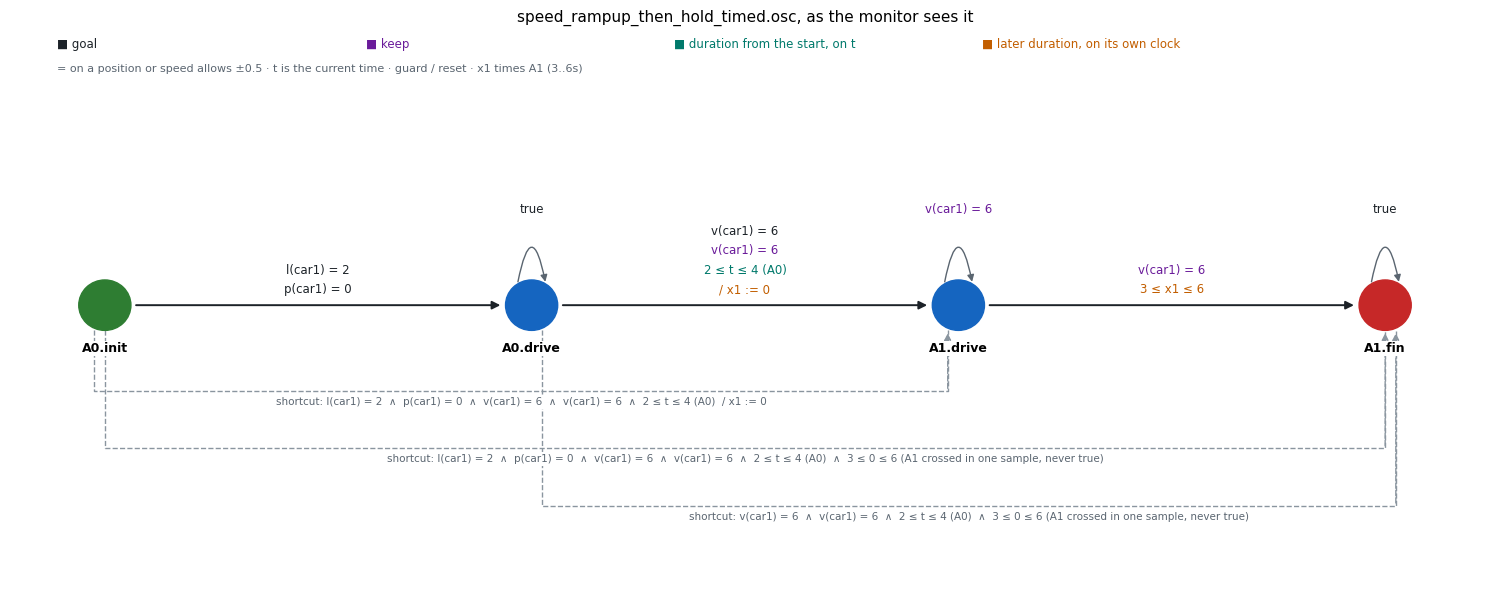

In [17]:
from demo_pipeline import draw_monitor_automaton
fig = draw_monitor_automaton(spec("speed_rampup_then_hold_timed.osc"),
                             "speed_rampup_then_hold_timed.osc, as the monitor sees it")
fig.savefig(os.path.join(OUT, "monitor_automaton.png"), dpi=150)
plt.show()

In [18]:
import contextlib, io, re
import networkx as nx
from monitoring.Monitor import Monitor, covered_locations, duration_regions, skipped_chains, TIME_VARIABLE

example = spec("speed_rampup_then_hold_timed.osc")
print(open(example).read())
mon = Monitor.from_osc2_file(example)
T = mon._translation_graph
name = lambda node: " | ".join(map(str, node)) if isinstance(node, tuple) else str(node)

keeps = [(covered_locations(inv, T.graph.nodes), inv) for inv in T.invariants]
anchored, timed = duration_regions(T)
print("what covers what:")
for covered, inv in keeps:
    print(f"  keep {inv.constraint}   covers {sorted(map(name, covered))}")
for covered, d in anchored:
    print(f"  {d}   covers {sorted(map(name, covered))}, starts with the scenario: a guard on current_t")
for covered, d in timed:
    print(f"  {d}   covers {sorted(map(name, covered))}, starts later: a clock per run")

def parts(source, target, crossed, goals):
    # the keep that applies: target covered, or the step into the final location leaving a covered one
    last = crossed[-1]
    keep = [str(inv.constraint) for covered, inv in keeps
            if target in covered or (target == T.final and last in covered)]
    guard = [f"{d.low} <= current_t <= {d.high}" for covered, d in anchored
             if target not in covered and any(n in covered for n in crossed)]
    clock = [f"start the clock of {d.source.split()[-1]}" for covered, d in timed
             if target in covered and source not in covered]
    clock += [f"check {d.low} <= current_t - start <= {d.high}" for covered, d in timed
              if target not in covered and any(n in covered for n in crossed)]
    return {"from": name(source), "to": name(target), "goals": " and ".join(goals) or "true",
            "keep": " and ".join(keep), "duration guard": " and ".join(guard), "clock": "; ".join(clock)}

path = next(nx.all_simple_paths(T.graph, T.initial, T.final))
rows = []
for u, v in zip(path, path[1:]):
    rows.append(dict(parts(u, v, [u], sorted(map(str, T[u, v]))), kind="edge"))
for node in path[1:]:
    rows.append(dict(parts(node, node, [node], []), kind="self loop"))
for source, target, chain in skipped_chains(T.graph):
    goals = sorted({str(c) for edge in chain for c in T[edge]})
    rows.append(dict(parts(source, target, [e[0] for e in chain], goals), kind="shortcut"))
order = {n: k for k, n in enumerate(path)}
table = pd.DataFrame(rows).sort_values(["from", "kind"], key=lambda s: s.map(lambda x: order.get(x, x) if isinstance(x, str) else x))
with pd.option_context("display.max_colwidth", None):
    display(table.set_index(["from", "to", "kind"]).replace("", "·"))

def pretty(formula):
    text, atom = str(formula), r"[A-Za-z_]+(?:\([A-Za-z0-9_]+\))?|-?\d+(?:\.\d+)?"
    while True:
        shorter = re.sub(rf"\(({atom})\)", r"\1", text)
        if shorter == text:
            return text
        text = shorter

aut = mon.syma_aut
a0, a1 = (next(l for l in aut.locations if str(l.id) == n) for n in ("A0.drive", "A1.drive"))
print("the same transition A0.drive -> A1.drive as the monitor stores it, with the tolerance spelled out:")
for key, s, t, con in aut.outgoing[a0]:
    if t is a1:
        print("  ", pretty(con.formula))

# The speed_rampup_then_hold.osc scenario, with a duration on the first segment as well. Every
# simulated car starts from rest and needs about two seconds to reach 6mps. Without a duration on the
# ramp the plan starts the car at 6mps right away, since its start speed is free, and spends no time
# accelerating, so the simulation gets far less time for the hold than the plan promised. With the
# monitor's clocks that shows up as a broken duration on the second segment.

scenario ramp_up_then_hold:
    car1: car

    do serial:
        A0: car1.drive(duration: [2s..4s]) with:
            lane(2, at: start)
            position(0m, at: start)
            speed(6mps, at: end)

        A1: car1.drive(duration: [3s..6s]) with:
            speed(6mps, at: all)

what covers what:
  keep v(car1) == 6.0   covers ['A1.drive']
  duration[the invocation A0.drive](2..4s)   covers ['A0.drive'], starts with the scenario: a guard on current_t
  duration[the invocation A1.drive](3..6s)   covers ['A1.dr

goals  \
from     to       kind                                                            
A0.init  A0.drive edge                          l(car1) == 2 and p(car1) == 0.0   
         A1.drive shortcut   l(car1) == 2 and p(car1) == 0.0 and v(car1) == 6.0   
         A1.fin   shortcut   l(car1) == 2 and p(car1) == 0.0 and v(car1) == 6.0   
A0.drive A1.drive edge                                           v(car1) == 6.0   
         A0.drive self loop                                                true   
         A1.fin   shortcut                                       v(car1) == 6.0   
A1.drive A1.fin   edge                                                     true   
         A1.drive self loop                                                true   
A1.fin   A1.fin   self loop                                                true   

                                       keep       duration guard  \
from     to       kind                                             
A0.init  A0.drive edge                    ·                    ·   
         A1.drive shortcut   v(car1) == 6.0  2 <= current_t <= 4   
         A1.fin   shortcut   v(car1) == 6.0  2 <= current_t <= 4   
A0.drive A1.drive edge       v(car1) == 6.0  2 <= current_t <= 4   
         A0.drive self loop               ·                    ·   
         A1.fin   shortcut   v(car1) == 6.0  2 <= current_t <= 4   
A1.drive A1.fin   edge       v(car1) == 6.0                    ·   
         A1.drive self loop  v(car1) == 6.0                    ·   
A1.fin   A1.fin   self loop               ·                    ·   

                                                         clock  
from     to       kind                                          
A0.init  A0.drive edge                                       ·  
         A1.drive shortcut         start the clock of A1.drive  
         A1.fin   shortcut   check 3 <= current_t - start <= 6  
A0.drive A1.drive edge             start the clock of A1.drive  
         A0.drive self loop                                  ·  
         A1.fin   shortcut   check 3 <= current_t - start <= 6  
A1.drive A1.fin   edge       check 3 <= current_t - start <= 6  
         A1.drive self loop                                  ·  
A1.fin   A1.fin   self loop                                  ·

the same transition A0.drive -> A1.drive as the monitor stores it, with the tolerance spelled out:
   ((((v(car1) - 6.0) <= 0.5) and ((6.0 - v(car1)) <= 0.5)) and (((v(car1) - 6.0) <= 0.5) and ((6.0 - v(car1)) <= 0.5))) and ((current_t >= 2) and (current_t <= 4))


### The clocks during a run

The plan's own trace, sampled three times per second, run through the monitor. Each row lists the
locations where some run is alive after that sample, and for runs in A1, the times at which their clock
started. Several start times live side by side: those are the different ways to split the trace into
A0 and A1 that are still possible. A1's duration then only keeps the runs whose A1 lasted 3 to 6
seconds.

In [19]:
from run_monitor_tests import stretch, valuations_from_plan
with contextlib.redirect_stdout(io.StringIO()):
    ex_plans, _, _ = plan_for("speed_rampup_then_hold_timed.osc", imax=14)
trace = stretch(valuations_from_plan(ex_plans[0]))
print("the plan: car1 speeds", speeds_of(ex_plans[0], "car1"), " goal times", goal_witnesses(ex_plans[0]))

mon.initialize()   # the clocks are needed here, so this is a TimedBooleanMonitor
rows = []
for k, row in enumerate(trace):
    mon.update(row)
    alive = defaultdict(set)
    for location, starts in mon.monitor.configurations:
        alive[str(location.id)].add(", ".join(f"{start:.2f}s" for _, start in starts) or "none")
    if k % 3 == 2 or k == len(trace) - 1:
        rows.append({"t": round(row[TIME_VARIABLE], 2), "car1 speed": row["v(car1)"],
                     "alive in": ", ".join(sorted(alive)) or "nowhere",
                     "clock of A1 started at": "; ".join(sorted(alive.get("A1.drive", set()))) or "·"})
display(pd.DataFrame(rows).set_index("t"))
final = next(l for l in mon.syma_aut.locations if l.final)
print("verdict:", "accepted" if not mon.state[final] else "rejected")

the plan: car1 speeds [0, 6, 6, 6, 6, 6]  goal times [(2, 5)]


,car1 speed,alive in,clock of A1 started at
t,,,
0.67,0,A0.drive,·
1.67,6,A0.drive,·
2.67,6,"A0.drive, A1.drive",2.00s; 2.33s; 2.67s
3.67,6,"A0.drive, A1.drive",2.00s; 2.33s; 2.67s; 3.00s; 3.33s; 3.67s
4.67,6,"A0.drive, A1.drive",2.00s; 2.33s; 2.67s; 3.00s; 3.33s; 3.67s; 4.00s
5.67,6,"A0.drive, A1.drive, A1.fin",2.00s; 2.33s; 2.67s; 3.00s; 3.33s; 3.67s; 4.00s


verdict: accepted


## 6b. The monitor's automaton, nested durations

**Spec.** `tests/duration_nested_deep.osc` from section 5b: durations on the scenario, on a `parallel` and
a `serial` inside it, and on single invocations inside those.

**What to look at.** The three durations that start with the scenario, the scenario itself, `first` and
`a`, are guards on `t`, each tagged with its owner. The three that start later get their own clocks:
`x1` for `second`, `x2` for `c`, `x3` for `d`. Leaving the parallel starts two clocks at once, because
it starts both `second` and `c`. Leaving `d` checks two at once, because the end of `d` is also the end of
`second`. The dashed shortcuts that would cross `c` or `d` within one sample are never true, since both
have to last at least a second.

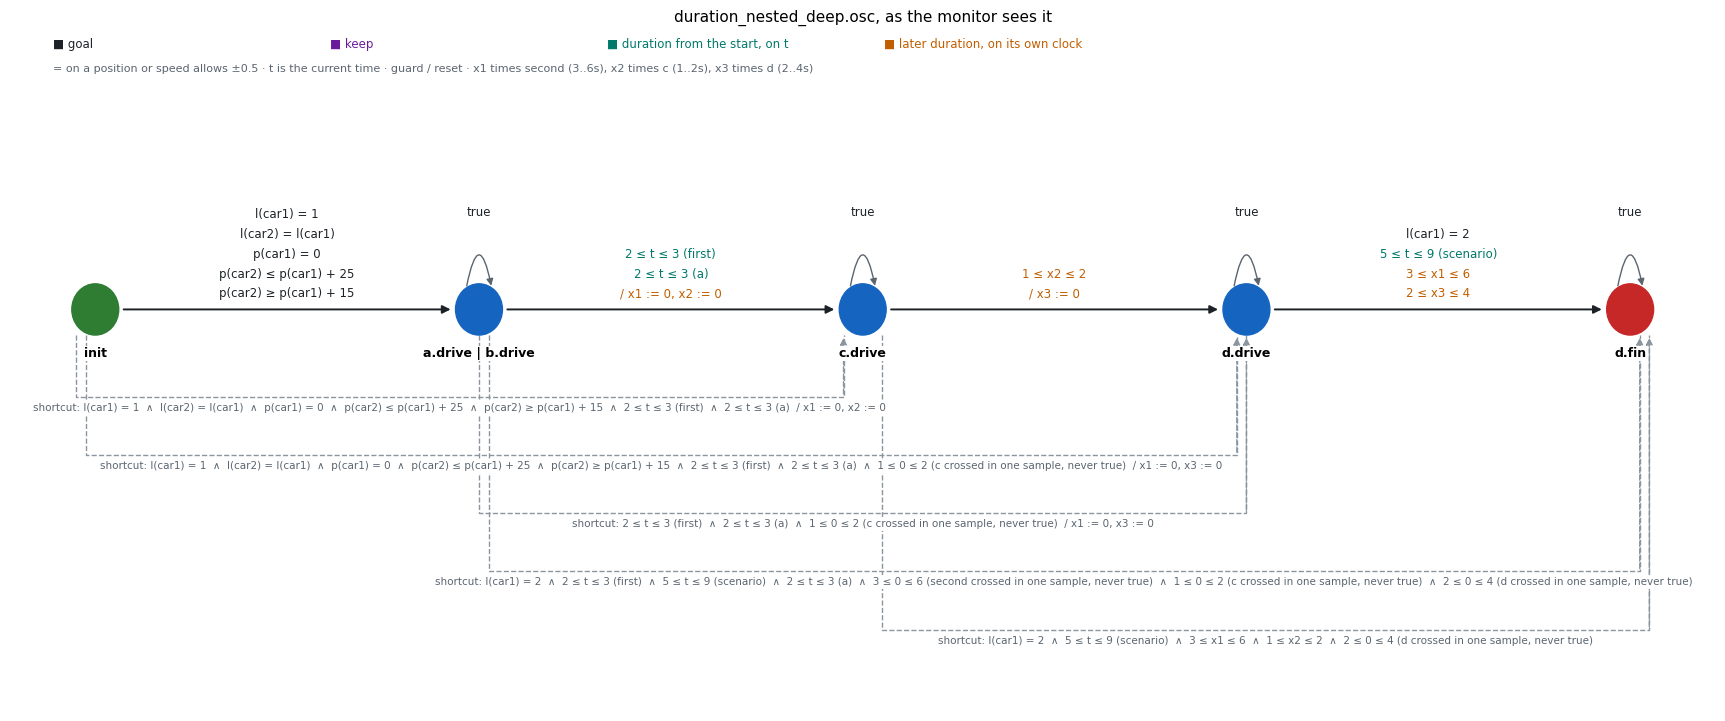

In [20]:
fig = draw_monitor_automaton(spec("duration_nested_deep.osc"),
                             "duration_nested_deep.osc, as the monitor sees it")
fig.savefig(os.path.join(OUT, "monitor_automaton_nested.png"), dpi=150)
plt.show()

## 6c. The monitor's automaton with a choice, `one_of`

**Spec.** `tests/one_of_nested.osc`. After a first segment car1 either moves left in one segment, or
moves right and keeps that lane for a second segment. Durations sit on the scenario, on the first segment,
on each alternative and on the parts of the longer one, and the keep only on its last part.

**What to look at.** `one_of` turns into a branch: two alternatives of different length leave `start`
and meet again at `fin`. Each alternative starts its own clocks on the way in. Shortcuts are not drawn
here, there are eight of them, and they are listed below the figure instead.

**Nondeterminism.** The monitor does not pick an alternative. On every sample each run continues along
every transition whose guard holds, so runs in both alternatives live side by side until the trace rules
one out, and the trace is accepted when any of them reaches `fin`. The planner, in contrast, commits to
one path through the graph and plans only that. A keep or duration inside an alternative it did not take
does not apply to that plan. Before this example the planner raised an error for those instead.

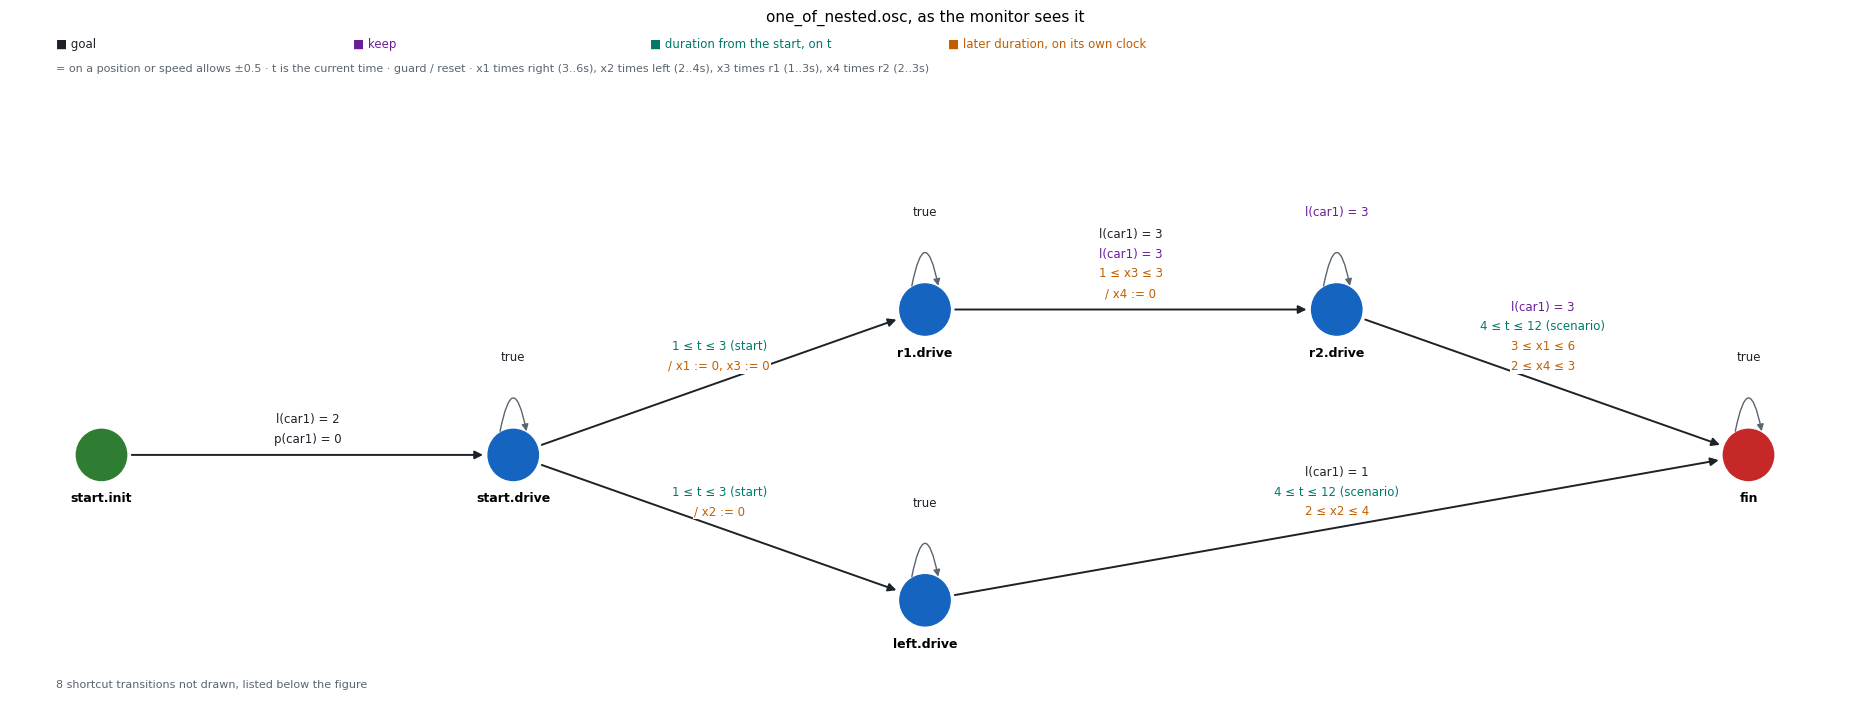

guard / reset
from        to                                                                                                                                                                                                                                                       
start.init  left.drive                                                                                                                                                                                   l(car1) = 2  ∧  p(car1) = 0  ∧  1 ≤ t ≤ 3 (start)  / x2 := 0
            r1.drive                                                                                                                                                                            l(car1) = 2  ∧  p(car1) = 0  ∧  1 ≤ t ≤ 3 (start)  / x1 := 0, x3 := 0
            r2.drive                                                                                       l(car1) = 2  ∧  l(car1) = 3  ∧  p(car1) = 0  ∧  l(car1) = 3  ∧  1 ≤ t ≤ 3 (start)  ∧  1 ≤ 0 ≤ 3 (r1 crossed in one sample, never true)  / x1 := 0, x4 := 0
            fin                                                                                                    l(car1) = 1  ∧  l(car1) = 2  ∧  p(car1) = 0  ∧  4 ≤ t ≤ 12 (scenario)  ∧  1 ≤ t ≤ 3 (start)  ∧  2 ≤ 0 ≤ 4 (left crossed in one sample, never true)
start.drive r2.drive                                                                                                                       l(car1) = 3  ∧  l(car1) = 3  ∧  1 ≤ t ≤ 3 (start)  ∧  1 ≤ 0 ≤ 3 (r1 crossed in one sample, never true)  / x1 := 0, x4 := 0
            fin         l(car1) = 3  ∧  l(car1) = 3  ∧  4 ≤ t ≤ 12 (scenario)  ∧  1 ≤ t ≤ 3 (start)  ∧  3 ≤ 0 ≤ 6 (right crossed in one sample, never true)  ∧  1 ≤ 0 ≤ 3 (r1 crossed in one sample, never true)  ∧  2 ≤ 0 ≤ 3 (r2 crossed in one sample, never true)
            fin                                                                                                                                    l(car1) = 1  ∧  4 ≤ t ≤ 12 (scenario)  ∧  1 ≤ t ≤ 3 (start)  ∧  2 ≤ 0 ≤ 4 (left crossed in one sample, never true)
r1.drive    fin                                                                                                              l(car1) = 3  ∧  l(car1) = 3  ∧  4 ≤ t ≤ 12 (scenario)  ∧  3 ≤ x1 ≤ 6  ∧  1 ≤ x3 ≤ 3  ∧  2 ≤ 0 ≤ 3 (r2 crossed in one sample, never true)

In [21]:
fig = draw_monitor_automaton(spec("one_of_nested.osc"), "one_of_nested.osc, as the monitor sees it")
fig.savefig(os.path.join(OUT, "monitor_automaton_one_of.png"), dpi=150)
plt.show()
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(fig.shortcuts, columns=["from", "to", "guard / reset"]).set_index(["from", "to"]))

The planner's path for this spec, and the monitor following the plan's own trace. Each row lists the
locations where some run is alive after that sample. A run is alive while it can still continue, which
does not mean it will reach the end: runs waiting in `r1` would need lane 3, which never comes.

In [22]:
with contextlib.redirect_stdout(io.StringIO()):
    choice_plans, choice_out, _ = plan_for("one_of_nested.osc", imax=14)
print("the planner's path: goal times", goal_witnesses(choice_plans[0]), " car1 lanes", lanes_of(choice_plans[0], "car1"))
print("durations it encoded, only those on its path:")
show_lines(f"{choice_out}/instance.lp", ["% duration"])

choice_monitor = Monitor.from_osc2_file(spec("one_of_nested.osc"))
choice_monitor.initialize()
rows = []
for k, row in enumerate(stretch(valuations_from_plan(choice_plans[0]))):
    choice_monitor.update(row)
    if k % 3 == 2:
        alive = sorted({str(location.id) for location, _ in choice_monitor.monitor.configurations})
        rows.append({"t": round(row[TIME_VARIABLE], 2), "car1 lane": row["l(car1)"], "alive in": ", ".join(alive)})
display(pd.DataFrame(rows).set_index("t"))
final = next(l for l in choice_monitor.syma_aut.locations if l.final)
print("verdict:", "accepted" if not choice_monitor.state[final] else "rejected")

the planner's path: goal times [(1, 4), (2, 4)]  car1 lanes [2, 2, 2, 1, 1]
durations it encoded, only those on its path:
% duration[serial](4..12s): from 0 to T2
% duration[the invocation left.drive](2..4s): from T1 to T2
% duration[the invocation start.drive](1..3s): from 0 to T1


,car1 lane,alive in
t,,
0.67,2,start.drive
1.67,2,"left.drive, r1.drive, start.drive"
2.67,2,"left.drive, r1.drive, start.drive"
3.67,1,"left.drive, r1.drive, start.drive"
4.67,1,"fin, left.drive, r1.drive, start.drive"


verdict: accepted


## 7. Experiment: can the simulation hold a requested speed

**Finding.** Frenetix's velocity planner reads only the first goal state of a planning problem. Our
plans have one goal state per waypoint, so after the first one Frenetix had no speed target and
overshot. The patch aims at the current waypoint and clamps to its speed window.

**Spec.** `tests/speed_rampup_then_hold.osc`: reach 6mps, then hold it.

**Settings.** `ROADLOGIC_VELOCITY_PATCH=0` or `1`. The patch changes nothing inside Frenetix, it is a
wrapper in `commonroad_extensions/scenario_execution/velocity_patch.py`.

In [23]:
from commonroad_extensions.scenario_execution import velocity_patch
show_code(velocity_patch.calculate_desired_velocity, 35)

commonroad_extensions/scenario_execution/velocity_patch.py:67

   67  def calculate_desired_velocity(self, x_0, s_position) -> float:
   68      """Aim for the current waypoint, inside the speed window the plan asked for."""
   69      goal_state = current_goal_state(self.planning_problem, x_0.time_step)
   70      if goal_state is None:
   71          return getattr(self, _ATTRIBUTE)(x_0, s_position)
   72  
   73      bounds = velocity_bounds(goal_state)
   74  
   75      target = None
   76      position = getattr(goal_state, "position", None)
   77      center = getattr(position, "center", None) if position is not None else None
   78      interval = getattr(goal_state, "time_step", None)
   79      if center is not None and interval is not None:
   80          goal_s = self._calculate_goal_s_position([center])
   81          # aim at the middle of the arrival window, as the original does
   82          remaining_steps = (interval.start + interval.end) / 2 - x_0.time_step
   83   

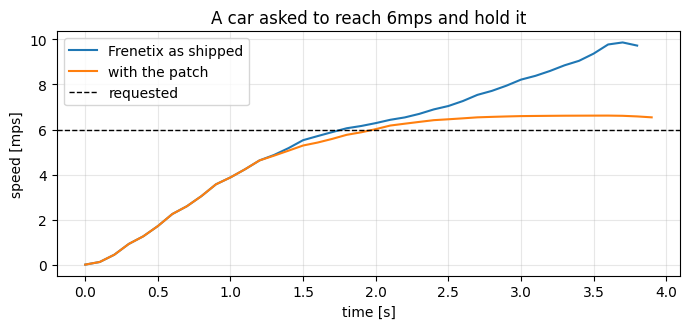

Frenetix as shipped,with the patch

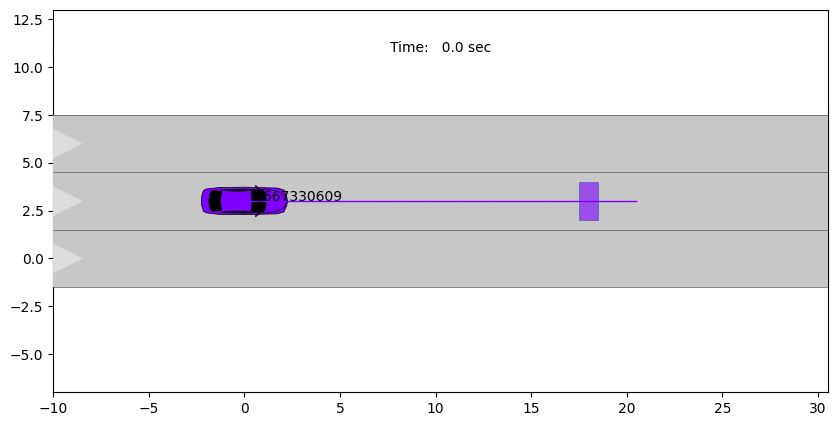
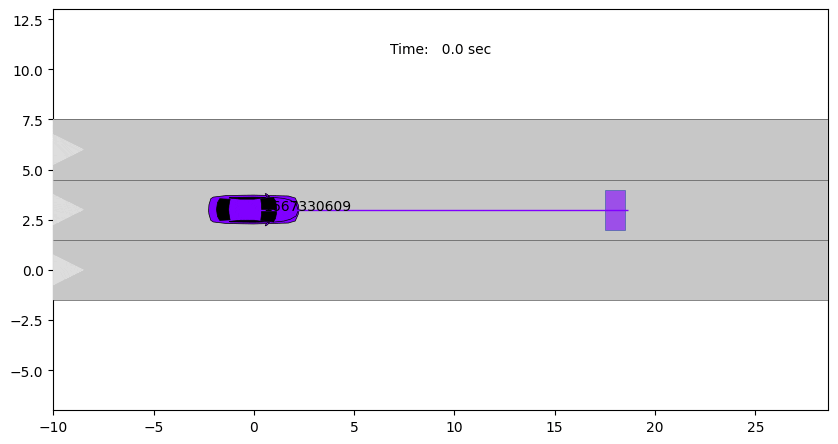

In [24]:
stock = run_experiment("e7_speed_without_patch", spec("speed_rampup_then_hold.osc"), RECOMMENDED)
patched = run_experiment("e7_speed_with_patch", spec("speed_rampup_then_hold.osc"), PATCHED)

fig, ax = plt.subplots(figsize=(7, 3.4))
for label, name in (("Frenetix as shipped", "e7_speed_without_patch"), ("with the patch", "e7_speed_with_patch")):
    frame = pd.read_csv(os.path.join(simulation_folder(name), "CURRV.csv")).sort_values("time")
    ax.plot(frame["time"], frame["velocity"], label=label)
ax.axhline(6, color="black", linestyle="--", linewidth=1, label="requested")
ax.set_xlabel("time [s]"); ax.set_ylabel("speed [mps]"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("A car asked to reach 6mps and hold it")
fig.tight_layout(); fig.savefig(os.path.join(OUT, "e7_speed_curves.png"), dpi=150); plt.show()

show_images([("Frenetix as shipped", f"{stock}/simulation.gif"), ("with the patch", f"{patched}/simulation.gif")])

## 8. Known problem, and a fix: the patch caused a collision with two cars

**Finding.** With the patch on as committed, the two-car overtake from section 1 crashes after 2.1s,
and so does the paper's own benchmark, after 3.5s. car1 crawls
at 1.7 m/s and ego, accelerating normally, rear-ends it before its lane change.

**Cause.** A bug in how the plan's speed reached Frenetix. In `dynamics.lp` a car's position at t is
its position at t-1 plus its speed at t-1, so the speed the plan stores at a waypoint is the speed the
car *leaves* it with. car1 reaches its t=4 waypoint at 8 m/s and then slows to 1, so it was given the
window 0 to 2 m/s, and the patch held it there from the start.

**Three fixes tried,** each behind a switch, defaults untouched:

| switch | idea |
|---|---|
| `ROADLOGIC_VELOCITY_PATCH_MODE=average` | drop the clamp, only aim to reach each waypoint on time |
| `ROADLOGIC_GOAL_VELOCITY_SOURCE=segment` | window from the plan's average speed over the stretch to the waypoint |
| `+ ROADLOGIC_GOAL_VELOCITY_SCOPE=constrained` | and only for cars whose speed the spec constrains |

Every simulated car starts from rest and the plans do not, so cars run behind the plan's schedule.
Keeping time then means driving faster than planned, which is right for an overtake and wrong for a
car asked to hold a speed. The third fix settles it by asking the specification which one it wants.
The table reads the runs from `demo_output/`, each with its `commands.sh`.

### 8a. ELI5: the problem and the fix, step by step

**The picture to keep in mind.** The planner writes a *timetable*: where each car is at every whole
second. Frenetix, the simulated driver, never sees the whole timetable. It gets a few *bus stops*
(waypoints): "be here between 4.0s and 5.0s". Each stop can also come with a *speed sign*,
"pass this stop at 0 to 2 m/s". The velocity patch is a cruise control that reads the next stop and its
sign and picks the driver's target speed.

The crash comes from one wrong number on one sign. The steps below follow that number from the plan
to the crash, all with the stored run of the two-car overtake (spec `tests/keep_scenario_scope.osc`,
shown in section 1: ego overtakes car1, car1 must stay in lane 2).

**Step 1. What the plan says.** Below is the plan, then the one rule of `dynamics.lp` that moves a car.
The new position is the old position plus the **old** speed. So the speed stored at step t is the speed
that carries the car from t to t+1, the speed it *leaves* t with. The figure draws car1's plan that way.
Every one-second leg is labelled with the speed driving it.

Look at the stop at t=4. car1 drives the leg 3 to 4 at 8 m/s, so it *arrives* fast. The speed stored at
t=4 is 1 m/s, because the plan brakes hard right after. Both are correct for the plan. The bug is which
one ended up on the sign.

last step: 9
goal times, one tuple per valid split: [(3, 4, 9), (3, 5, 9), (4, 4, 9), (4, 5, 9), (5, 5, 9)]

car1
  t [s]          0    1    2    3    4    5    6    7    8    9
  position      10   11   14   17   25   26   27   34   36   37
  lane           2    2    2    2    2    2    2    2    2    2
  speed [mps]    1    3    3    8    1    1    7    2    1    3

ego
  t [s]          0    1    2    3    4    5    6    7    8    9
  position       0    1    8   14   26   36   44   45   54   61
  lane           2    2    2    1    1    1    1    1    1    2
  speed [mps]    1    7    6   12   10    8    1    9    7    1

planning/asp/encoding/dynamics.lp, how a step moves a car:
    holds(state(V,loc(S,L),dyn(Vel_lon,Vel_lat)), t) :-
    		holds(state(V,loc(S_prev,L_prev),dyn(Vel_lon_prev, Vel_lat_prev)), t-1),
    		occurs(change_dynamics(V, Delta_Vel_lon, Vel_lat), t),
    		L = L_prev + Vel_lat_prev,
    		S = S_prev + Vel_lon_prev,
    		Vel_lon = Vel_lon_prev + Delta_Vel_lon,
 

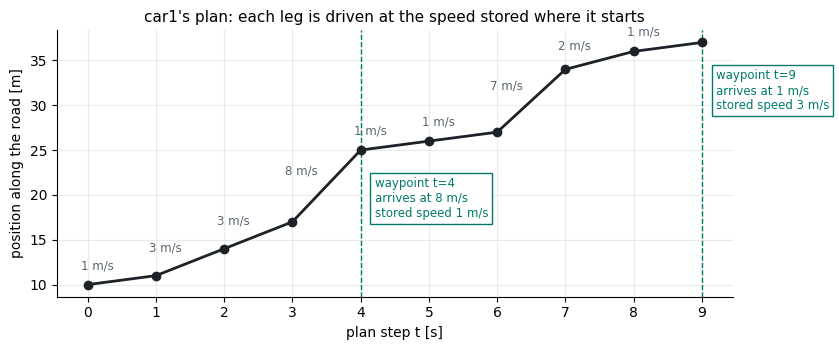

In [25]:
from demo_pipeline import (load_plan, plan_text, plot_gap, plot_plan_legs, plot_simulated,
                           plot_speed_windows, scenario_windows, speed_window)
ROOT = os.getcwd()
overtake_plan = load_plan("e8_overtake_with_patch")
print(plan_text(overtake_plan))
print("planning/asp/encoding/dynamics.lp, how a step moves a car:")
for line in open(os.path.join(ROOT, "planning/asp/encoding/dynamics.lp")).read().splitlines()[37:44]:
    print("   ", line.rstrip())
waypoints = [step for step, _, _ in scenario_windows("e8_overtake_with_patch")["car1"]]
print(f"\nwaypoints handed to the simulator, by plan step: {waypoints}")
plot_plan_legs(overtake_plan, "car1", waypoints);

**Step 2. What goes on the speed sign.** `map_plan.py` turns each stop into a CommonRoad goal state. It
can fill in the sign in three ways (`ROADLOGIC_GOAL_VELOCITY_SOURCE`), always widened by ±1 m/s:

| source | the sign says | for car1 at t=4 |
|---|---|---|
| `departure` (as committed) | the speed stored at the stop, which is the one the car *leaves* with | 1, so 0..2 |
| `segment` | the average speed from the previous stop: distance / time | (25 − 10) / 4 = 3.75, so 2.75..4.75 |
| `range` | lowest to highest speed the plan drives on the way there | 1..8, so 0..9 |

The grey dots in the figure are the speeds the plan really drives on each stretch. A good sign
should agree with them. `departure` misses them on three of the four stretches. Worst are car1 at t=4,
told 0..2 while the plan drives up to 8, and ego at t=9, told 0..2 while the plan drives 7 to 10.
The table under the figure checks the computed signs against the scenario files the runs used.

computed here in e8_overtake_with_patch/scenario.xml  \
source    car  stop                                                        
departure ego  t=4          9..11                                  9..11   
               t=9           0..2                                   0..2   
          car1 t=4           0..2                                   0..2   
               t=9           2..4                                   2..4   
segment   ego  t=4       5.5..7.5                                    NaN   
               t=9           6..8                                    NaN   
          car1 t=4     2.75..4.75                                    NaN   
               t=9       1.4..3.4                                    NaN   

                    in f2_overtake_segment/scenario.xml  
source    car  stop                                      
departure ego  t=4                                  NaN  
               t=9                                  NaN  
          car1 t=4                                  NaN  
               t=9                                  NaN  
segment   ego  t=4                             5.5..7.5  
               t=9                                 6..8  
          car1 t=4                           2.75..4.75  
               t=9                             1.4..3.4

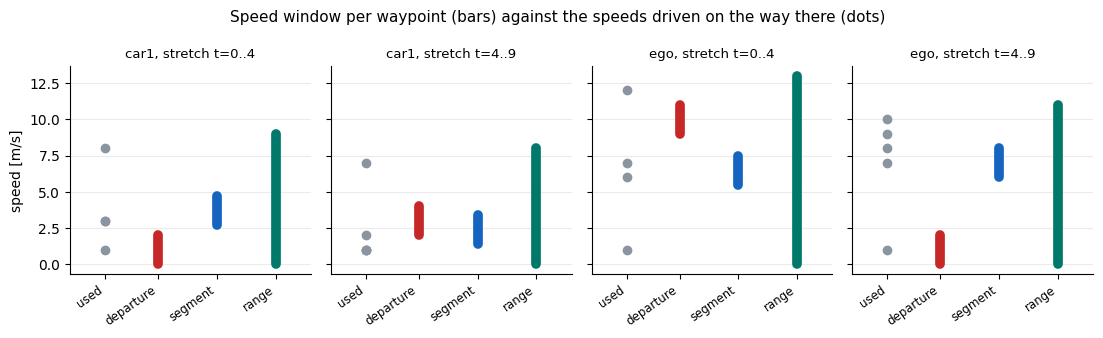

In [26]:
plot_speed_windows(overtake_plan, ["car1", "ego"], waypoints);
check = []
for run, source in [("e8_overtake_with_patch", "departure"), ("f2_overtake_segment", "segment")]:
    for car, rows in scenario_windows(run).items():
        previous = 0
        for step, low, high in rows:
            check.append({"source": source, "car": car, "stop": f"t={step}",
                          "computed here": "%g..%g" % speed_window(overtake_plan, car, step, previous, source),
                          f"in {run}/scenario.xml": f"{low:g}..{high:g}"})
            previous = step
display(pd.DataFrame(check).set_index(["source", "car", "stop"]))

**Step 3. What the cruise control does with a wrong sign.** The patch (`velocity_patch.py`) does two things:

1. *Timing:* target = distance to the next stop / time left to it.
2. *Clamp:* push that target into the sign's window.

At the start car1 is at 10 m and its first stop is at 25 m, about 4.5s away. Timing alone says
15 / 4.5 ≈ 3.3 m/s. The sign says 0..2, so the clamp makes it **2 m/s**. car1 crawls (red line, left).
ego's first sign says 9..11, so ego speeds up as usual (red line, right). The shaded bands are the signs
of the run with the patch as committed.

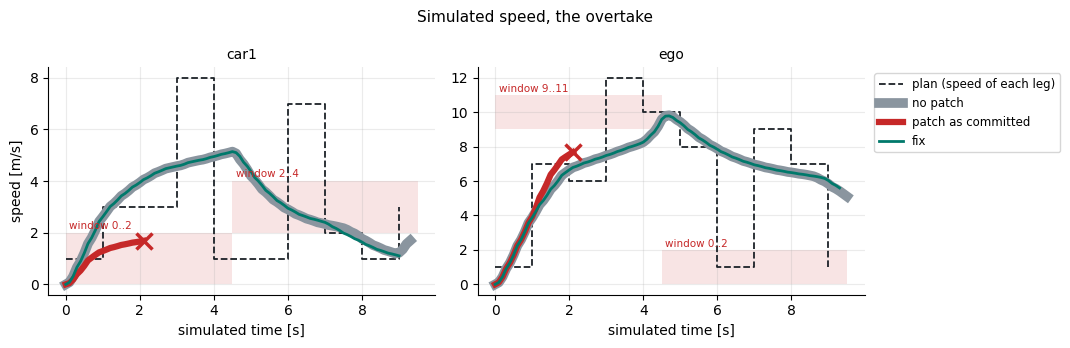

In [27]:
overtake_runs = {"no patch": "e1_keep_one_lane", "patch as committed": "e8_overtake_with_patch",
                 "fix": "f3_overtake"}
plot_simulated(overtake_runs, ["car1", "ego"], model=overtake_plan, windows_from="e8_overtake_with_patch",
               title="Simulated speed, the overtake");

**Step 4. Why that is a crash.** ego starts 10 m behind car1 in the *same lane* and only moves left
after a few seconds. With car1 at walking pace the gap closes before ego changes lane. The trace stops at
2.1s with the cars' centres 3.7 m apart, less than one car length (about 4.5 m). Without the patch, and
with the fix, car1 drives away at its normal pace. The gap then stays above 5 m until ego is in the
other lane, and from about 4.5s on ego is ahead.

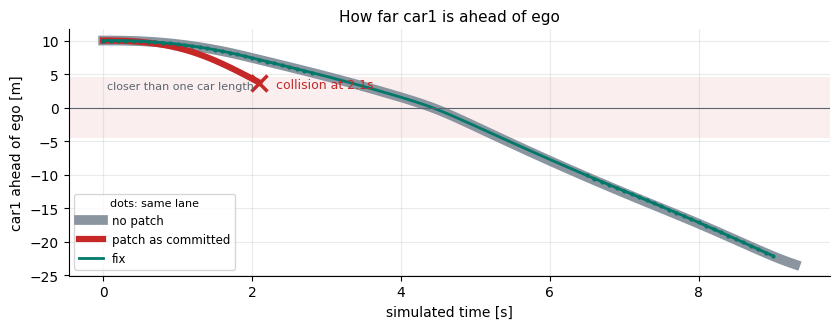

In [28]:
plot_gap(overtake_runs, "car1", "ego");

**Step 5. Why a better sign alone is not enough.** The obvious repair is a correct sign (`segment` or
`range`). There is a second effect underneath, though. **Every simulated car starts from rest, and the
plan does not.** So a simulated car is always *behind* its timetable, and timing (rule 1) then says
"drive faster than planned to catch up".

Whether catching up is right depends on the spec:

* In the overtake, nobody's speed is specified. Catching up is right, and ego *must* reach its stops on
  time or the overtake does not happen. A sign there can only hurt.
* In `tests/speed_rampup_then_hold.osc` the spec says car1 holds 6 m/s. The plan drives 6 m/s from
  t=0, the simulated car starts at 0 and is behind from the first moment. Timing alone (`average` mode,
  and the stock planner without patch) races up to 9.9 m/s to catch up, which breaks the spec. With the
  sign 5..7 the clamp holds it at 6.6 at most.


scenario ramp_up_then_hold:
    car1: car

    do serial:
        A0: car1.drive() with:
            lane(2, at: start)
            position(0m, at: start)
            speed(6mps, at: end)

        A1: car1.drive(duration: [3s..6s]) with:
            speed(6mps, at: all)

last step: 3
goal times, one tuple per valid split: [(0, 3)]
keep windows (keep, from, to): [(1, 0, 3)]

car1
  t [s]          0    1    2    3
  position       0    6   12   18
  lane           2    2    2    2
  speed [mps]    6    6    6    6



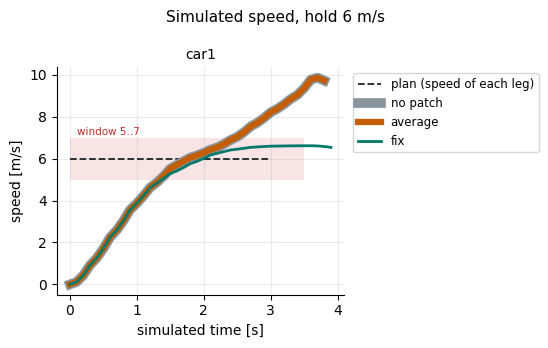

In [29]:
ramp_plan = load_plan("e7_speed_with_patch")
print("".join(l for l in open(os.path.join(OUT, "e7_speed_with_patch", "spec.osc")) if not l.startswith("#")))
print(plan_text(ramp_plan))
plot_simulated({"no patch": "e7_speed_without_patch", "average": "f1_ramp_average",
                "fix": "f3_ramp"}, ["car1"], model=ramp_plan,
               windows_from="f3_ramp", title="Simulated speed, hold 6 m/s");

**Step 6. The fix, in two parts.**

1. **A correct sign.** It comes from the speeds the plan drives on the way to the stop, not from the
   speed it leaves with: `ROADLOGIC_GOAL_VELOCITY_SOURCE=range` (or `segment`, the first try).
2. **A sign only where the spec asks for one.** `ROADLOGIC_GOAL_VELOCITY_SCOPE=constrained` puts a
   sign only on cars whose speed the spec constrains (`speed_constrained_actors` in
   `create_plan_scenarios.py`). The others are steered by timing alone, so they catch up as needed.

What each car gets under the fix:

| run | car | speed constrained by the spec? | sign | result |
|---|---|---|---|---|
| overtake | car1, ego | no | none | same as without patch, no collision |
| hold 6 m/s | car1 | yes | 5..7 | peak 6.6 instead of 9.9 |

In one sentence: the sign showed the speed *after* the stop instead of the speed *before* it. And even a
correct sign must only be shown to cars whose speed the spec cares about, because simulated cars run
late and the others need to be allowed to catch up.

**Still open.** Cars still start from rest and lag the plan, so the fix does not remove the lag. It only
stops the speed sign from making things worse. The patch is off by default since `218a86e`, so the
default reproduces the paper. The table below gathers all runs.

In [30]:
cases = {
    "two-car overtake": ("tests/keep_scenario_scope.osc", {
        "no patch": "e1_keep_one_lane", "patch as committed": "e8_overtake_with_patch",
        "average": "f1_overtake_average", "segment": "f2_overtake_segment",
        "segment, constrained only": "f3_overtake"}),
    "benchmark exp_002": ("experiments_src/exp_002/in/spec.osc", {
        "no patch": "e9_benchmark", "patch as committed": "e8_benchmark_with_patch",
        "average": "f1_benchmark_average",
        "segment": "f2_benchmark_segment", "segment, constrained only": "f3_benchmark"}),
}
rows = defaultdict(dict)
for case, (case_spec, runs) in cases.items():
    for label, name in runs.items():
        if case == "two-car overtake":
            f = simulation_folder(name)
            rows[label][case] = f"{monitor_verdict(case_spec, f)}, {simulation_length(f):.1f}s"
        else:
            rows[label][case] = " / ".join(monitor_verdict(case_spec, simulation_folder(name, s))
                                           for s in ("scenario_0001", "scenario_0002"))
for label, name in {"no patch": "e7_speed_without_patch", "patch as committed": "e7_speed_with_patch",
                    "average": "f1_ramp_average", "segment": "f2_ramp_segment",
                    "segment, constrained only": "f3_ramp"}.items():
    v = pd.read_csv(os.path.join(simulation_folder(name), "CURRV.csv"))
    rows[label]["single car, hold 6 m/s"] = (f"peak {v.velocity.max():.2f}, "
                                             f"mean after 2s {v[v.time >= 2].velocity.mean():.2f}")
order = ["no patch", "patch as committed", "average", "segment", "segment, constrained only"]
display(pd.DataFrame(rows).T.loc[order, ["two-car overtake", "single car, hold 6 m/s", "benchmark exp_002"]].fillna("not run"))

,two-car overtake,"single car, hold 6 m/s",benchmark exp_002
no patch,"POSITIVE, 9.5s","peak 9.87, mean after 2s 8.01",POSITIVE / POSITIVE
patch as committed,"negative, 2.1s","peak 6.62, mean after 2s 6.49",negative / negative
average,"POSITIVE, 9.5s","peak 9.87, mean after 2s 8.01",POSITIVE / POSITIVE
segment,"POSITIVE, 9.6s","peak 6.62, mean after 2s 6.49",negative / negative
"segment, constrained only","POSITIVE, 9.3s","peak 6.62, mean after 2s 6.49",POSITIVE / POSITIVE


patch as committed: collision,with the fix

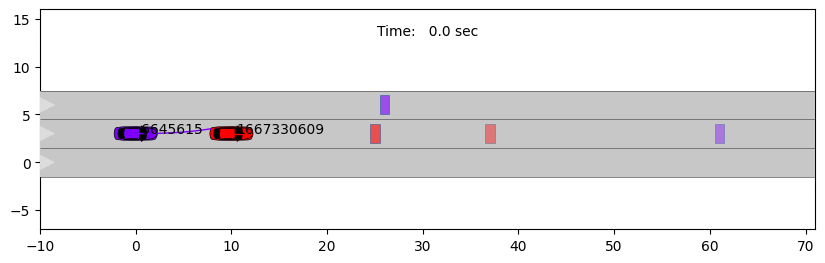
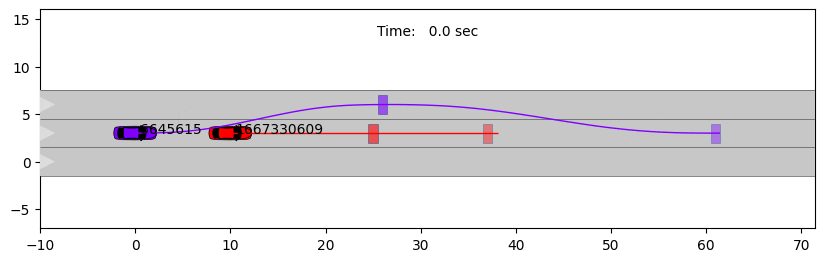

In [31]:
show_images([("patch as committed: collision", f"{OUT}/e8_overtake_with_patch/simulation.gif"),
             ("with the fix", f"{OUT}/f3_overtake/simulation.gif")])

**A side note from testing the fix.** `tests/speed_overtake_keep.osc` (car1 holds 5 m/s while ego
overtakes) collides in simulation with *any* settings, paper settings included, at about 7.5s. Its last
goal merges ego back only 5 to 10 m ahead of car1, which the motion planner cannot do safely. That is a
problem with the specification, the same one `keep.osc` had before its gap was widened to 13 to 25 m.
With the fix, car1's speed stays between 4.99 and 5.65 m/s there, against 4.99 to 7.16 without.

**Since then.** For a car whose speed the spec constrains, a window spanning the *range* of speeds
the plan uses on a stretch (`ROADLOGIC_GOAL_VELOCITY_SOURCE=range`) works better than the average,
which pinned an accelerating car to half its target speed (section 11). Cars without a speed
constraint get no window under the fix, so the overtake and benchmark rows hold unchanged.

## 9. Experiment: which verdict algebra

**Finding.** MinMax returns a number that mixes lanes and metres, one lane apart counting as one
metre apart. Plain boolean is meaningless on simulated floats, a position a fraction of a millimetre
off fails the whole trace. The new default is boolean with a 1e-3 tolerance on continuous values,
the same slack the summary script always applied to the MinMax cost. It has to agree with MinMax
on the benchmark, or every number in the paper moves.

**Spec.** `experiments_src/exp_002/in/spec.osc`, the paper's overtake, run with paper settings.

In [32]:
import math
from monitoring.Monitor import TolerantBooleanMonitor
from syma_arv.monitor.boolean import BooleanMonitor
from syma_arv.monitor.minmax import MinMaxMonitor
from monitoring.Monitor import Monitor

bench_spec = os.path.join("experiments_src", "exp_002", "in", "spec.osc")
run_experiment("e9_benchmark", bench_spec, PAPER, scenarios=2)

def final(spec_path, folder, ring):
    mon = Monitor.from_osc2_file(spec_path, ring=ring)
    mon.eval_trace(folder, log_name_override="nb_ring")
    return mon.state[[l for l in mon.syma_aut.locations if l.final][0]]

rows = []
for scenario in ("scenario_0001", "scenario_0002"):
    folder = simulation_folder("e9_benchmark", scenario)
    cost = float(final(bench_spec, folder, MinMaxMonitor))
    rows.append({"scenario": scenario, "minmax cost": cost,
                 "minmax verdict": "positive" if math.isclose(cost, 0, abs_tol=1e-3) else "negative",
                 "tolerant boolean": "positive" if not final(bench_spec, folder, TolerantBooleanMonitor) else "negative",
                 "strict boolean": "positive" if not final(bench_spec, folder, BooleanMonitor) else "negative"})
display(pd.DataFrame(rows).set_index("scenario"))

,minmax cost,minmax verdict,tolerant boolean,strict boolean
scenario,,,,
scenario_0001,0.0001,positive,positive,negative
scenario_0002,0.0001,positive,positive,negative


## 10. A speed keep needs a tolerance, and clocks

**What is new.** The planner's world is discrete, one unit is one metre or one mps. A simulated trace
is sampled every 0.1s and crosses 6.000 without landing on it, so `speed(6mps)` could never hold. A
required equality on a position or a speed now holds within half a unit: `EQUALITY_TOLERANCE = 0.5` in
`monitoring/Monitor.py`, overridable with `ROADLOGIC_EQUALITY_TOLERANCE`. Lanes stay exact. The value
may need tuning.

**The check.** Every simulated run in this notebook, with the tolerance off and on. Nothing about the
keeps or the benchmark changes. Only the speed hold does, and there the unpatched run, which reached
almost 10 m/s, passes too. Its keep window can shrink to the one moment the speed was near 6. A
duration on that segment prevents it, and section 11 checks one with a clock.

In [33]:
import monitoring.Monitor as MM

speeds = pd.read_csv(os.path.join(simulation_folder("e7_speed_with_patch"), "CURRV.csv"))["velocity"]
print(f"closest sample to 6.000: {abs(speeds - 6).min():.4f} mps off, "
      f"{(abs(speeds - 6) <= 1e-3).sum()} samples within 1e-3, {(abs(speeds - 6) <= 0.5).sum()} within 0.5\n")

# the same speed spec without the duration on its second segment, which the monitor cannot check yet
variant = os.path.join(OUT, "speed_hold_without_segment_duration.osc")
with open(variant, "w") as f:
    f.write(open(spec("speed_rampup_then_hold.osc")).read().replace("car1.drive(duration: [3s..6s])", "car1.drive()"))

runs = [("keep one lane", spec("keep_scenario_scope.osc"), "e1_keep_one_lane", "scenario_0001"),
        ("keep one lane, with the fix", spec("keep_scenario_scope.osc"), "f3_overtake", "scenario_0001"),
        ("keep two lanes", spec("keep_lane_change_from_rest.osc"), "e2_keep_two_lanes", "scenario_0001"),
        ("benchmark 1", bench_spec, "e9_benchmark", "scenario_0001"),
        ("benchmark 2", bench_spec, "e9_benchmark", "scenario_0002"),
        ("hold 6 m/s, patched (holds 6.5)", variant, "e7_speed_with_patch", "scenario_0001"),
        ("hold 6 m/s, unpatched (peaks 9.87)", variant, "e7_speed_without_patch", "scenario_0001")]
rows = []
for label, s, name, scenario in runs:
    row = {"run": label}
    for tol in (0.0, 0.5):
        MM.EQUALITY_TOLERANCE = tol
        MM.Monitor.from_osc2_file.__func__.cache_clear()
        row[f"tolerance {tol}"] = monitor_verdict(s, simulation_folder(name, scenario))
    rows.append(row)
MM.EQUALITY_TOLERANCE = 0.5
MM.Monitor.from_osc2_file.__func__.cache_clear()
display(pd.DataFrame(rows).set_index("run"))
print("the original spec, with its duration on the second segment:",
      monitor_verdict(spec("speed_rampup_then_hold.osc"), simulation_folder("e7_speed_with_patch")))

closest sample to 6.000: 0.0164 mps off, 0 samples within 1e-3, 10 within 0.5



,tolerance 0.0,tolerance 0.5
run,,
keep one lane,POSITIVE,POSITIVE
"keep one lane, with the fix",POSITIVE,POSITIVE
keep two lanes,POSITIVE,POSITIVE
benchmark 1,POSITIVE,POSITIVE
benchmark 2,POSITIVE,POSITIVE
"hold 6 m/s, patched (holds 6.5)",negative,POSITIVE
"hold 6 m/s, unpatched (peaks 9.87)",negative,POSITIVE


the original spec, with its duration on the second segment: negative


## 11. Clocks: a duration on any segment

**What is new.** A duration on a segment that starts partway through, like the 3 to 6 s hold below,
needs the time that segment began. The monitor follows many runs at once, one per way of splitting the
trace into segments, and they began it at different times. So the monitor now keeps, per run, the
time each open duration region was entered. Entering a region starts its clock, and leaving it checks
`low <= now - start <= high`. A duration on the top-level composition keeps its simple guard on the
current time from section 6, which stays inside plain symbolic automata. The clocks do not: they are
per-run state, which makes this a timed automaton. `ROADLOGIC_TIMED_MONITOR=0` switches them off.

**Spec.** `tests/speed_rampup_then_hold_timed.osc`: reach 6 m/s within 2 to 4 s, then hold it for 3 to
6 s. The duration on the ramp makes the plan spend time accelerating, as a real car must. Without it
the plan starts the car at 6 m/s, its start speed being free, and the hold in simulation comes out far
shorter than the plan promised.

**Command.** `python tests/run_monitor_tests.py duration_invocation.osc` runs the clock tests.

In [34]:
import monitoring.Monitor as MM
show_code(MM.TimedBooleanMonitor._clocks_after)

monitoring/Monitor.py:282

  282      def _clocks_after(self, starts, crossed, target, now):
  283          """The open regions after a step, or None when the step breaks a duration."""
  284          starts = dict(starts)
  285          for index, (covered, duration) in enumerate(self.regions):
  286              if index in starts:
  287                  if target not in covered:
  288                      if not duration.low <= now - starts.pop(index) <= duration.high:
  289                          return None
  290              elif target in covered:
  291                  starts[index] = now
  292              elif any(node in covered for node in crossed[1:]):
  293                  # a shortcut ran through the whole region in one step, so it lasted no time
  294                  if not duration.low <= 0 <= duration.high:
  295                      return None
  296          return tuple(sorted(starts.items()))


**What the clocks found.** Three simulations of the timed spec, plus the old run that peaked at
9.87 m/s. With the range windows the car holds 6 ± 0.5 from 2.9 s to the end of the run at 5.7 s, so
2.8 s. The spec asks for 3 s and the run is rejected, correctly. The planner lets a car change speed by
8 m/s in one second (`max_velocity_change_lon` in `constants.lp`), so the plan reaches 6 m/s in one
step, while the simulated car needs 2.9 s. Against a variant asking for a 2 s hold, the range fix passes
and every other run fails, the 9.87 run included. Before the clocks, that one passed.

,speed after 3s,hold 3s to 6s (the spec),hold 2s to 6s
run,,,
range windows (the fix),5.60 to 6.05,negative,POSITIVE
no patch,6.16 to 6.52,negative,negative
segment windows,3.18 to 6.03,negative,negative
"old spec's run, peaked at 9.87",8.22 to 9.87,negative,negative


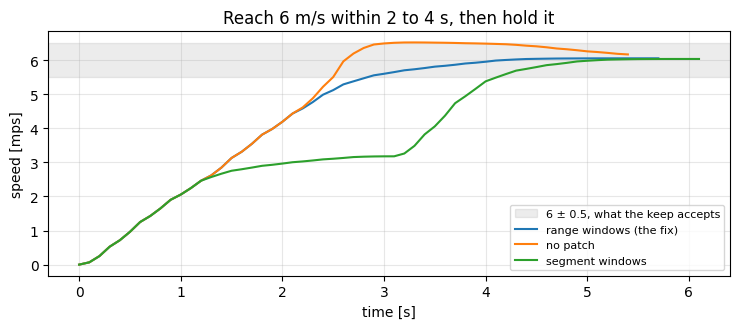

In [35]:
timed = spec("speed_rampup_then_hold_timed.osc")
two_seconds = os.path.join(OUT, "speed_hold_2s.osc")
with open(two_seconds, "w") as f:
    f.write(open(timed).read().replace("A1: car1.drive(duration: [3s..6s])", "A1: car1.drive(duration: [2s..6s])"))

runs = [("range windows (the fix)", "g2_timed_ramp_with_range_fix"),
        ("no patch", "g1_timed_ramp_without_patch"),
        ("segment windows", "g1_timed_ramp_with_fix"),
        ("old spec's run, peaked at 9.87", "e7_speed_without_patch")]
rows = []
for label, name in runs:
    v = pd.read_csv(os.path.join(simulation_folder(name), "CURRV.csv"))
    late = v[v.time >= 3].velocity
    rows.append({"run": label, "speed after 3s": f"{late.min():.2f} to {late.max():.2f}",
                 "hold 3s to 6s (the spec)": monitor_verdict(timed, simulation_folder(name)),
                 "hold 2s to 6s": monitor_verdict(two_seconds, simulation_folder(name))})
display(pd.DataFrame(rows).set_index("run"))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.axhspan(5.5, 6.5, color="grey", alpha=0.15, label="6 ± 0.5, what the keep accepts")
for label, name in runs[:3]:
    v = pd.read_csv(os.path.join(simulation_folder(name), "CURRV.csv")).sort_values("time")
    ax.plot(v.time, v.velocity, label=label)
ax.set_xlabel("time [s]"); ax.set_ylabel("speed [mps]"); ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="lower right")
ax.set_title("Reach 6 m/s within 2 to 4 s, then hold it")
fig.tight_layout(); fig.savefig(os.path.join(OUT, "g_timed_ramp_speeds.png"), dpi=150); plt.show()

## Where to continue

1. **Choose the default for the speed patch.** Recommended is the fix: speed windows from the range of
   planned speeds, only for cars whose speed the spec constrains
   (`ROADLOGIC_GOAL_VELOCITY_SOURCE=range`, `ROADLOGIC_GOAL_VELOCITY_SCOPE=constrained`). The other choice
   is the patch off. As committed, the paper's benchmark collides. The paper's settings stay one switch
   away either way: `ROADLOGIC_VELOCITY_PATCH=0 ROADLOGIC_GOAL_VELOCITY=0`.
2. **Calibrate the planner's acceleration** to the simulator. `max_velocity_change_lon = 8` lets a plan go
   from rest to 6 m/s in one second where a simulated car needs about three (section 11). This changes
   every plan, so it is a decision with consequences for the paper.
3. **Tune `EQUALITY_TOLERANCE`.** At 0.5 it rejects stock Frenetix for peaking at 6.52 (section 11).
4. **Widen the merge-back gap in `tests/speed_overtake_keep.osc`**, which collides with any settings.
5. **Speed experiments for the paper**, built from sections 7, 8, 10 and 11.
6. Smaller: soft `default` keeps and `remove_default` are still unsupported.

Every run in this notebook can be repeated from its `demo_output/<experiment>/commands.sh`.